# Perplexity Analysis — TAT German

This notebook runs the full statistical analysis and visualization pipeline.
It loops over three analysis settings (with outliers, without outliers, matched sample)
and produces the same set of plots and statistics for each.

In [33]:
import sys
import os
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, mannwhitneyu

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 120

# Make sure project root is on the path
sys.path.insert(0, os.path.abspath('.'))

from services.analysis_service import analysis_service, load_metadata, build_person_df
from services.plotting_service import plot_setting, plot_cross_setting, plot_advanced
from functions.analysis.statistics import (
    CLINICAL_VARS,
    group_comparison,
    clinical_correlations,
    residualize_ppl,
    nested_regression_models,
    steigers_z,
    compute_roc,
    logistic_cv_auc,
)
from functions.plotting.plots import (
    plot_roc_curves,
    plot_metrics_heatmap,
    plot_raw_vs_residualized,
)

## 1. Configuration

In [34]:
# Paths
SENTENCE_CSV = "/zi/home/esra.lenz/Documents/00_HITKIP/11_normative/mnm_ppl/data/TAT_german_utterances_with_perplexities.csv"
METADATA_CSV = "data/00_raw_data/Demografics_Speech_FOR2107.csv"
FIGURE_DIR = "figures"

# Model prefix for column names
MODEL = "qwen"

# Primary perplexity variable
PPL_VAR = f"{MODEL}_ppl_median"
WC_VAR = f"{MODEL}_total_words"

# Clinical variables
clinical_vars = CLINICAL_VARS
print(f"Clinical variables: {clinical_vars}")

Clinical variables: ['GAF', 'TLI_Impoverished', 'TLI_Disorganization', 'TLI_Non_specific']


## 2. Load data & prepare three analysis settings

In [35]:
df, settings = analysis_service(
    sentence_csv=SENTENCE_CSV,
    metadata_csv=METADATA_CSV,
    model_name=MODEL,
)

print(f"\nFull dataset: {len(df)} subjects")
print(f"Patients: {(df['is_patient'] == 1).sum()}, Controls: {(df['is_patient'] == 0).sum()}")

High-PPL sentence threshold (90th %ile of controls): 231.15
Matched sample: 157 patients + 157 controls
  with_outliers: 366 total (189 patients, 177 controls)
  without_outliers: 366 total (189 patients, 177 controls)
  matched: 314 total (157 patients, 157 controls)

Full dataset: 366 subjects
Patients: 189, Controls: 177


In [36]:
df.head()

,file_id,diagnosis,sex,age,education,comorbidity,GAF,verbal_IQ,TLI_Impoverished,TLI_Disorganization,...,qwen_ppl_median,qwen_ppl_std,qwen_ppl_p90,qwen_ppl_p75,qwen_ppl_cv,qwen_total_words,qwen_avg_words,qwen_n_sentences,qwen_n_high_ppl,qwen_prop_high_ppl
0,0006_3,MDD,male,30,13.0,0,65.0,NaN,0.0,2.25,...,42.727394,251.273414,152.678939,79.519564,2.622420,2098,17.056911,123,5,0.040650
1,0008_3,HC,female,24,13.0,0,82.0,107.0,1.0,0.25,...,26.764693,52.716038,97.538706,53.563033,1.131960,842,14.271186,59,2,0.033898
2,0011_3,MDD,male,52,9.0,1,79.0,94.0,0.0,1.00,...,60.138020,168.046061,305.688756,130.438055,1.365685,1587,12.398438,128,14,0.109375
3,0013_3,MDD,female,44,13.0,0,75.0,118.0,0.0,0.25,...,43.634248,1524.395697,263.394979,100.332198,5.407409,1701,15.605505,109,13,0.119266
4,0020_3,MDD,female,26,12.0,1,45.0,104.0,0.0,0.25,...,46.749204,2229.652663,283.802267,111.204231,5.935646,952,12.050633,79,10,0.126582


## 3. Loop: Group comparison & clinical correlations for all 3 settings


Setting: with_outliers | PPL variable: qwen_ppl_median
Saved: figures/with_outliers/01_group_boxplot.png


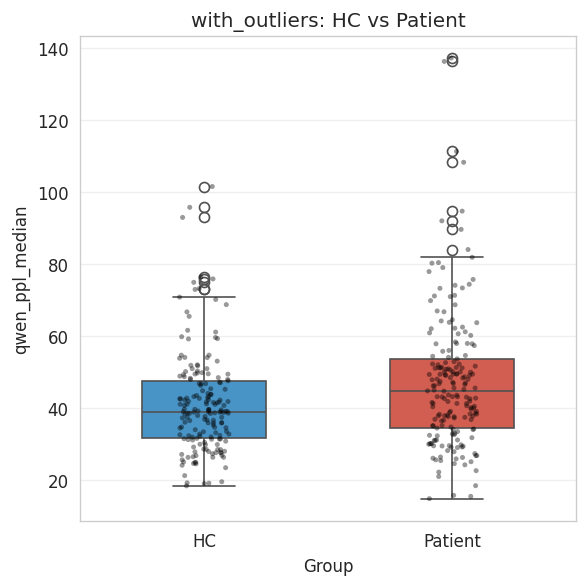


with_outliers — qwen_ppl_median:
  Variable: qwen_ppl_median
  Control (M±SD): 41.24±14.06
  Patient (M±SD): 47.29±19.22
  Control Median: 39.0090008613624
  Patient Median: 44.74777198748531
  t: 3.4155346940237017
  p(t): 0.0007083850798510544
  U: 20114.0
  p(MW): 0.0008123903292220418
  Cohens d: 0.3572577909969567
  r: -0.20252294263593695

Clinical correlations (with_outliers):
  Clinical Variable         r        p   n
                GAF -0.228861 0.001832 183
   TLI_Impoverished  0.206831 0.005605 178
TLI_Disorganization  0.084169 0.263985 178
   TLI_Non_specific  0.129458 0.085021 178
Saved: figures/with_outliers/02_clinical_scatter.png


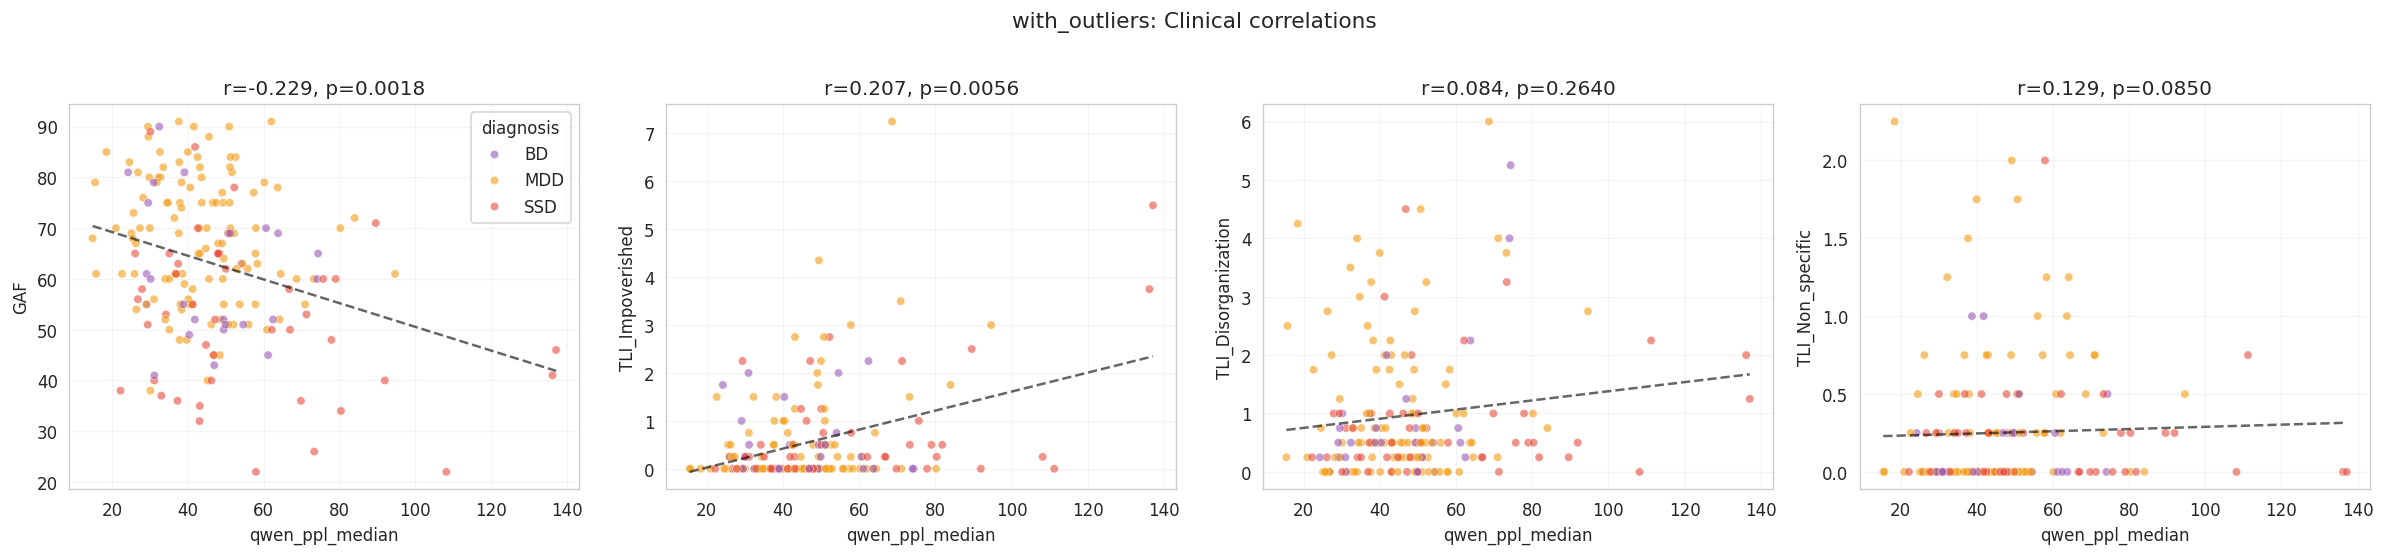

Saved: figures/with_outliers/03_diagnostic_groups.png


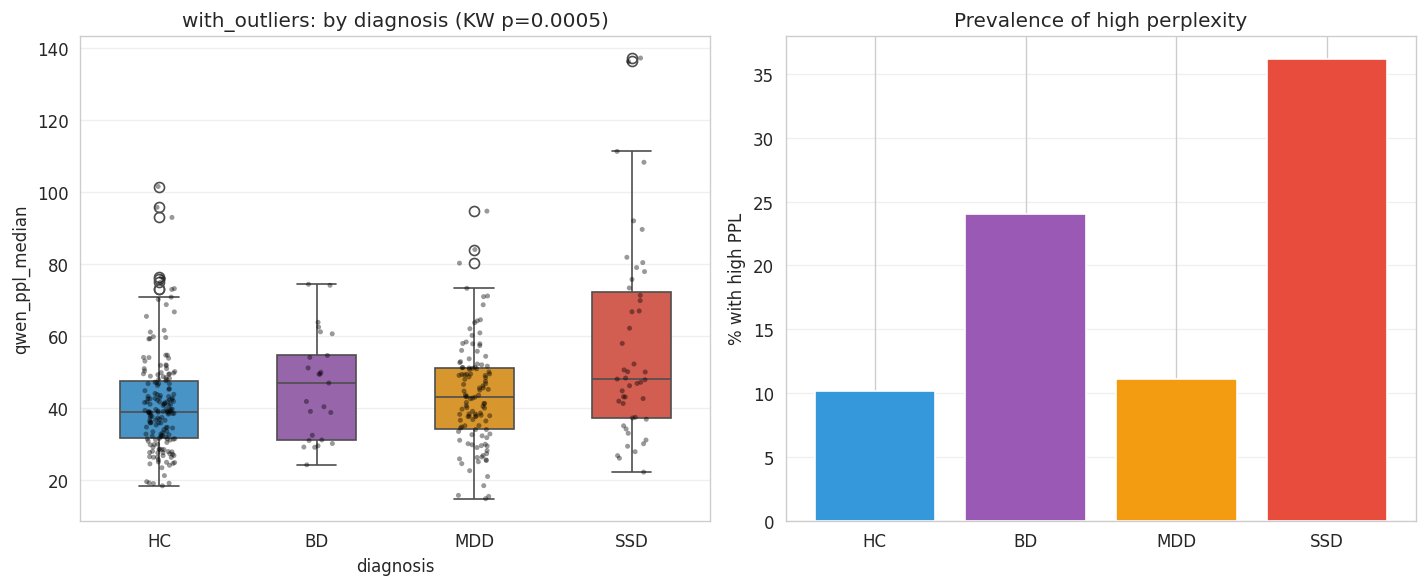

Saved: figures/with_outliers/04_extreme_groups.png


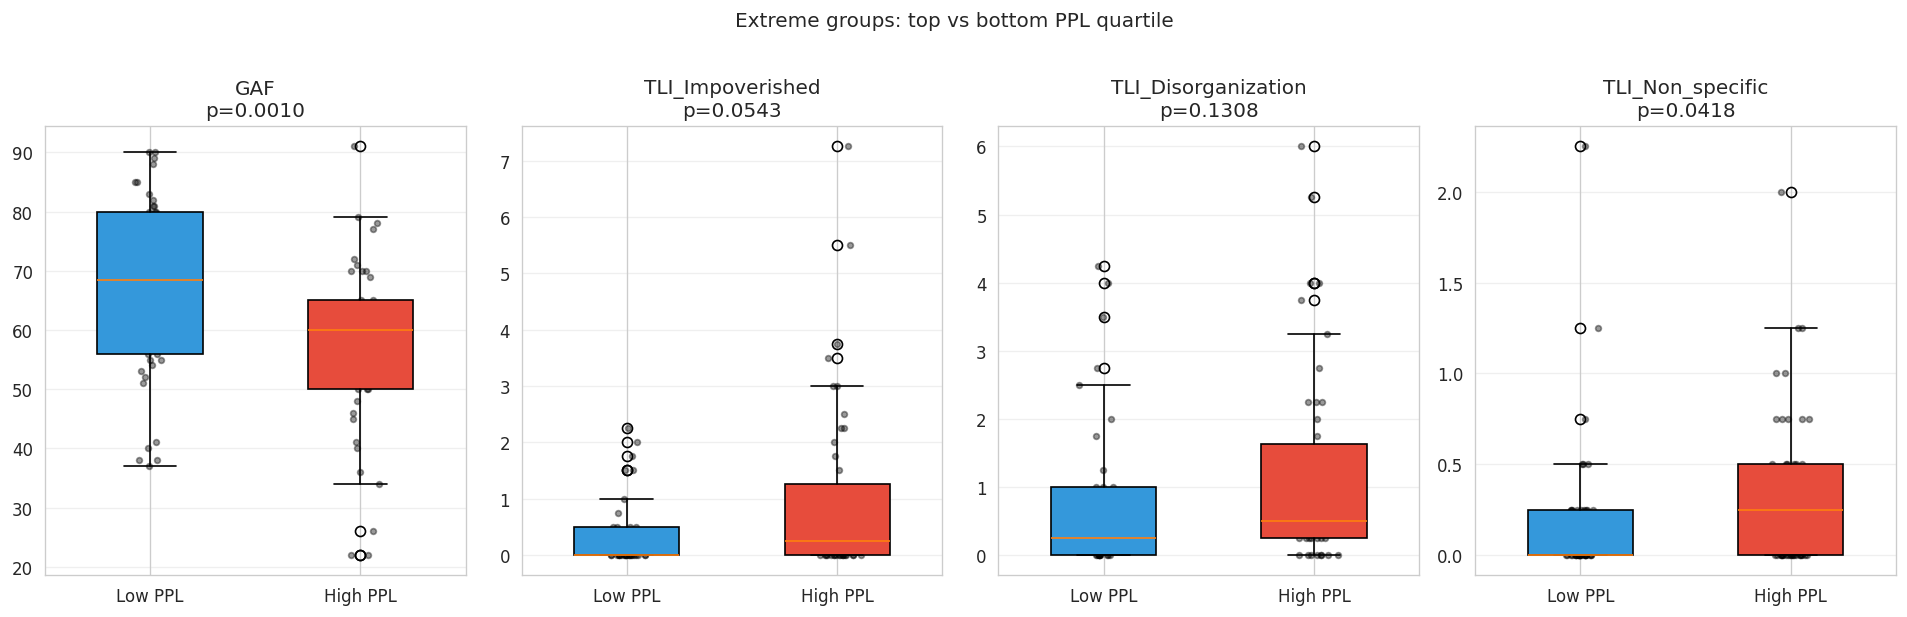

Saved: figures/with_outliers/05_tli_subscales.png


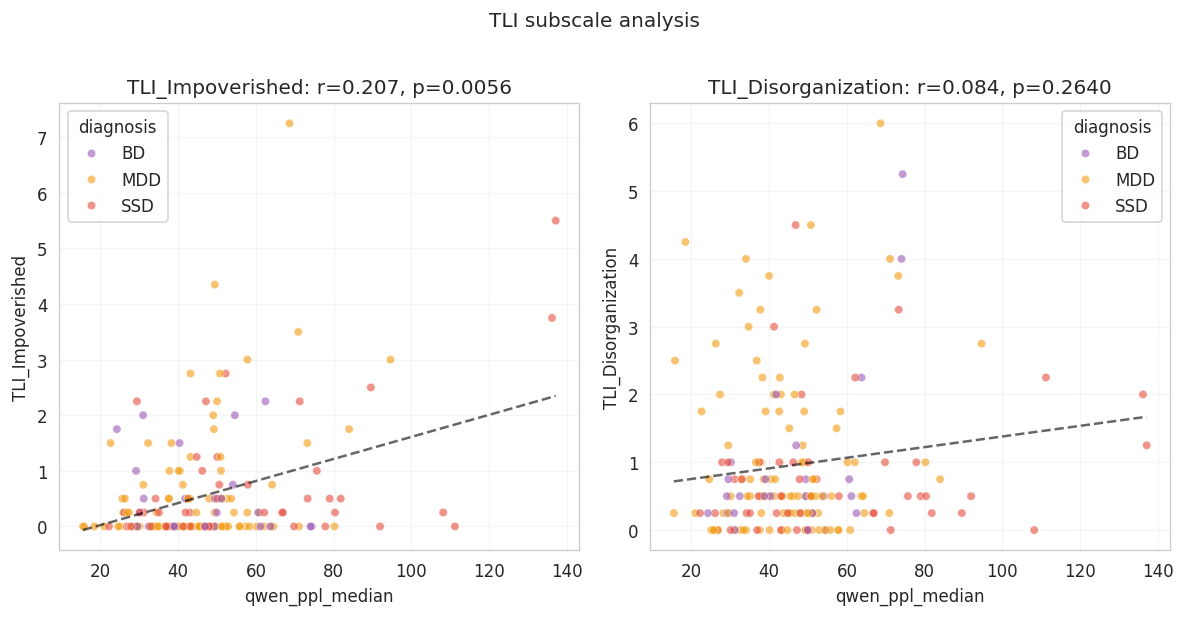


--- Deconfounding (with_outliers) ---
  Raw:          p(MW)=0.0008, d=0.357
  Residualized: p(MW)=0.0782, d=0.217

  Clinical correlations (raw vs residualized):
  Clinical Variable     r_raw    p_raw  n_raw   r_resid  p_resid  n_resid
                GAF -0.228861 0.001832    183 -0.114804 0.129212      176
   TLI_Impoverished  0.206831 0.005605    178 -0.003757 0.961215      170
TLI_Disorganization  0.084169 0.263985    178  0.143937 0.061119      170
   TLI_Non_specific  0.129458 0.085021    178  0.125981 0.101629      170

  Kruskal-Wallis — Raw: H=17.556, p=0.0005
  Kruskal-Wallis — Resid: H=6.881, p=0.0758
Saved: figures/with_outliers/deconfounded/raw_vs_residualized.png


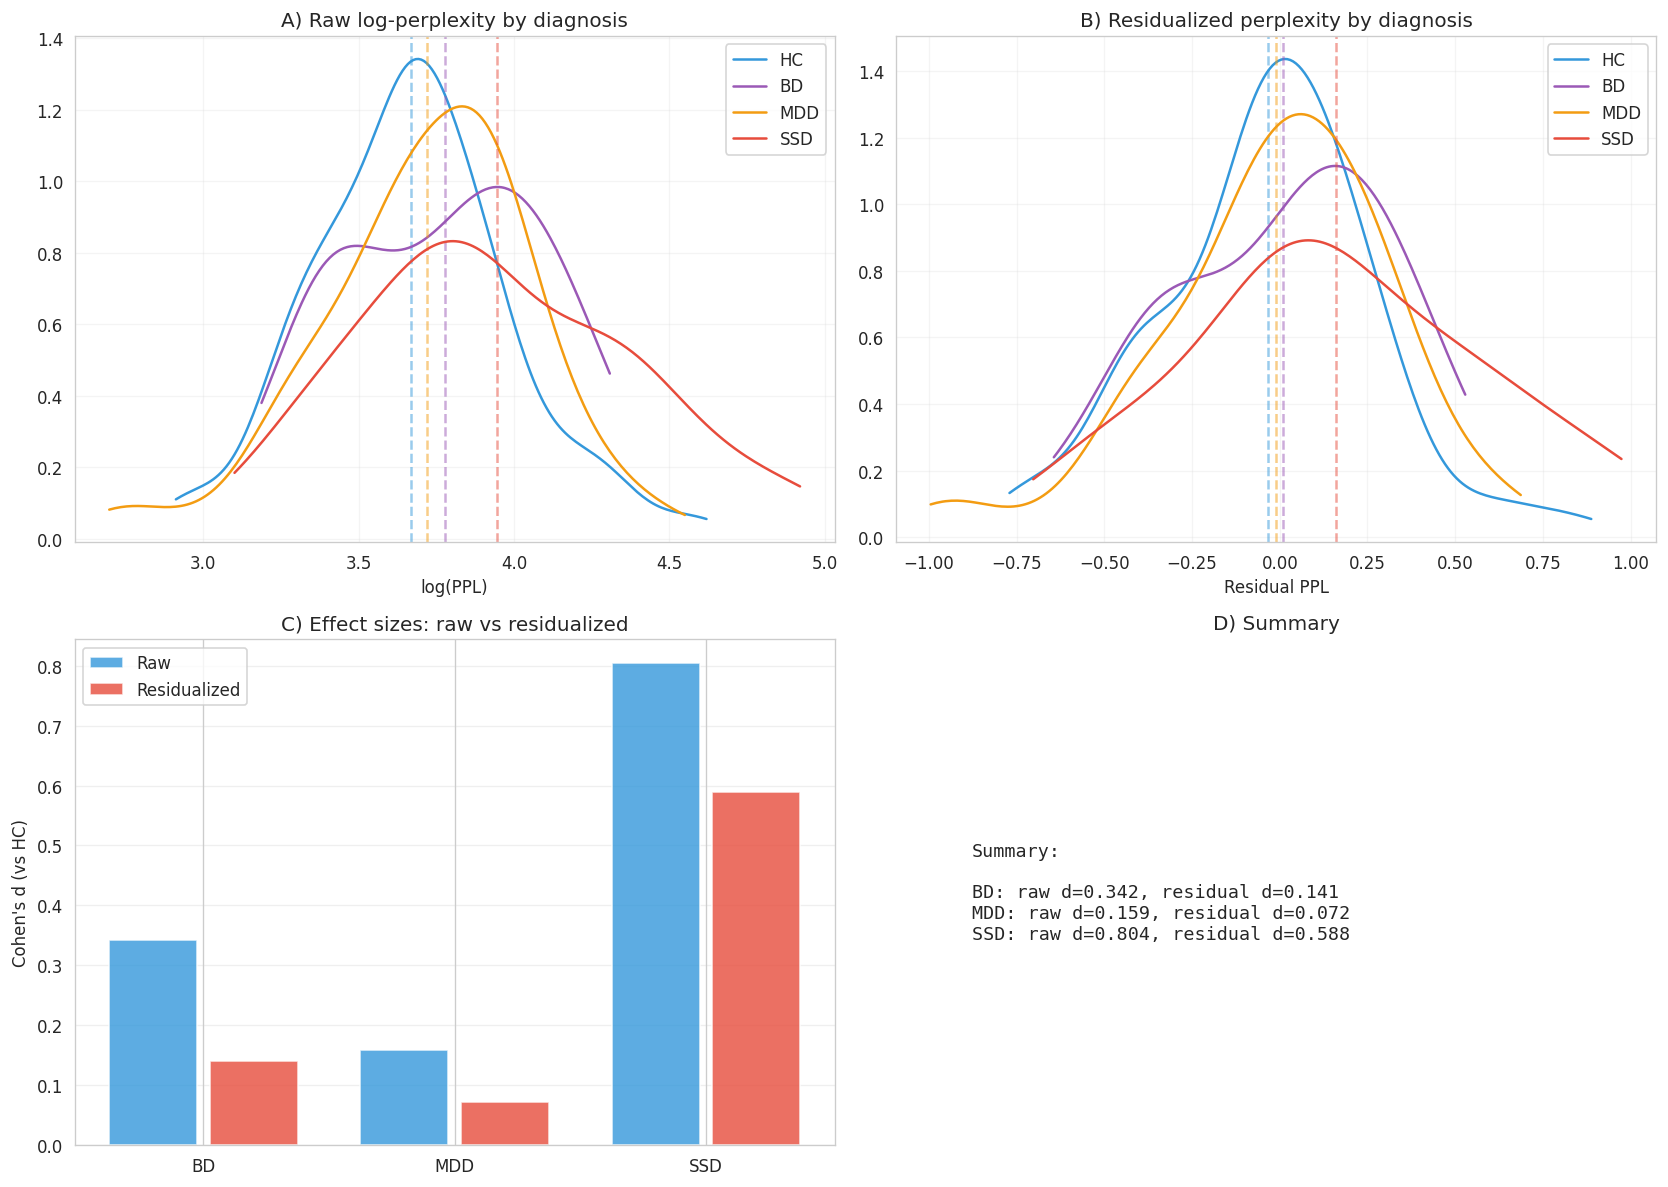

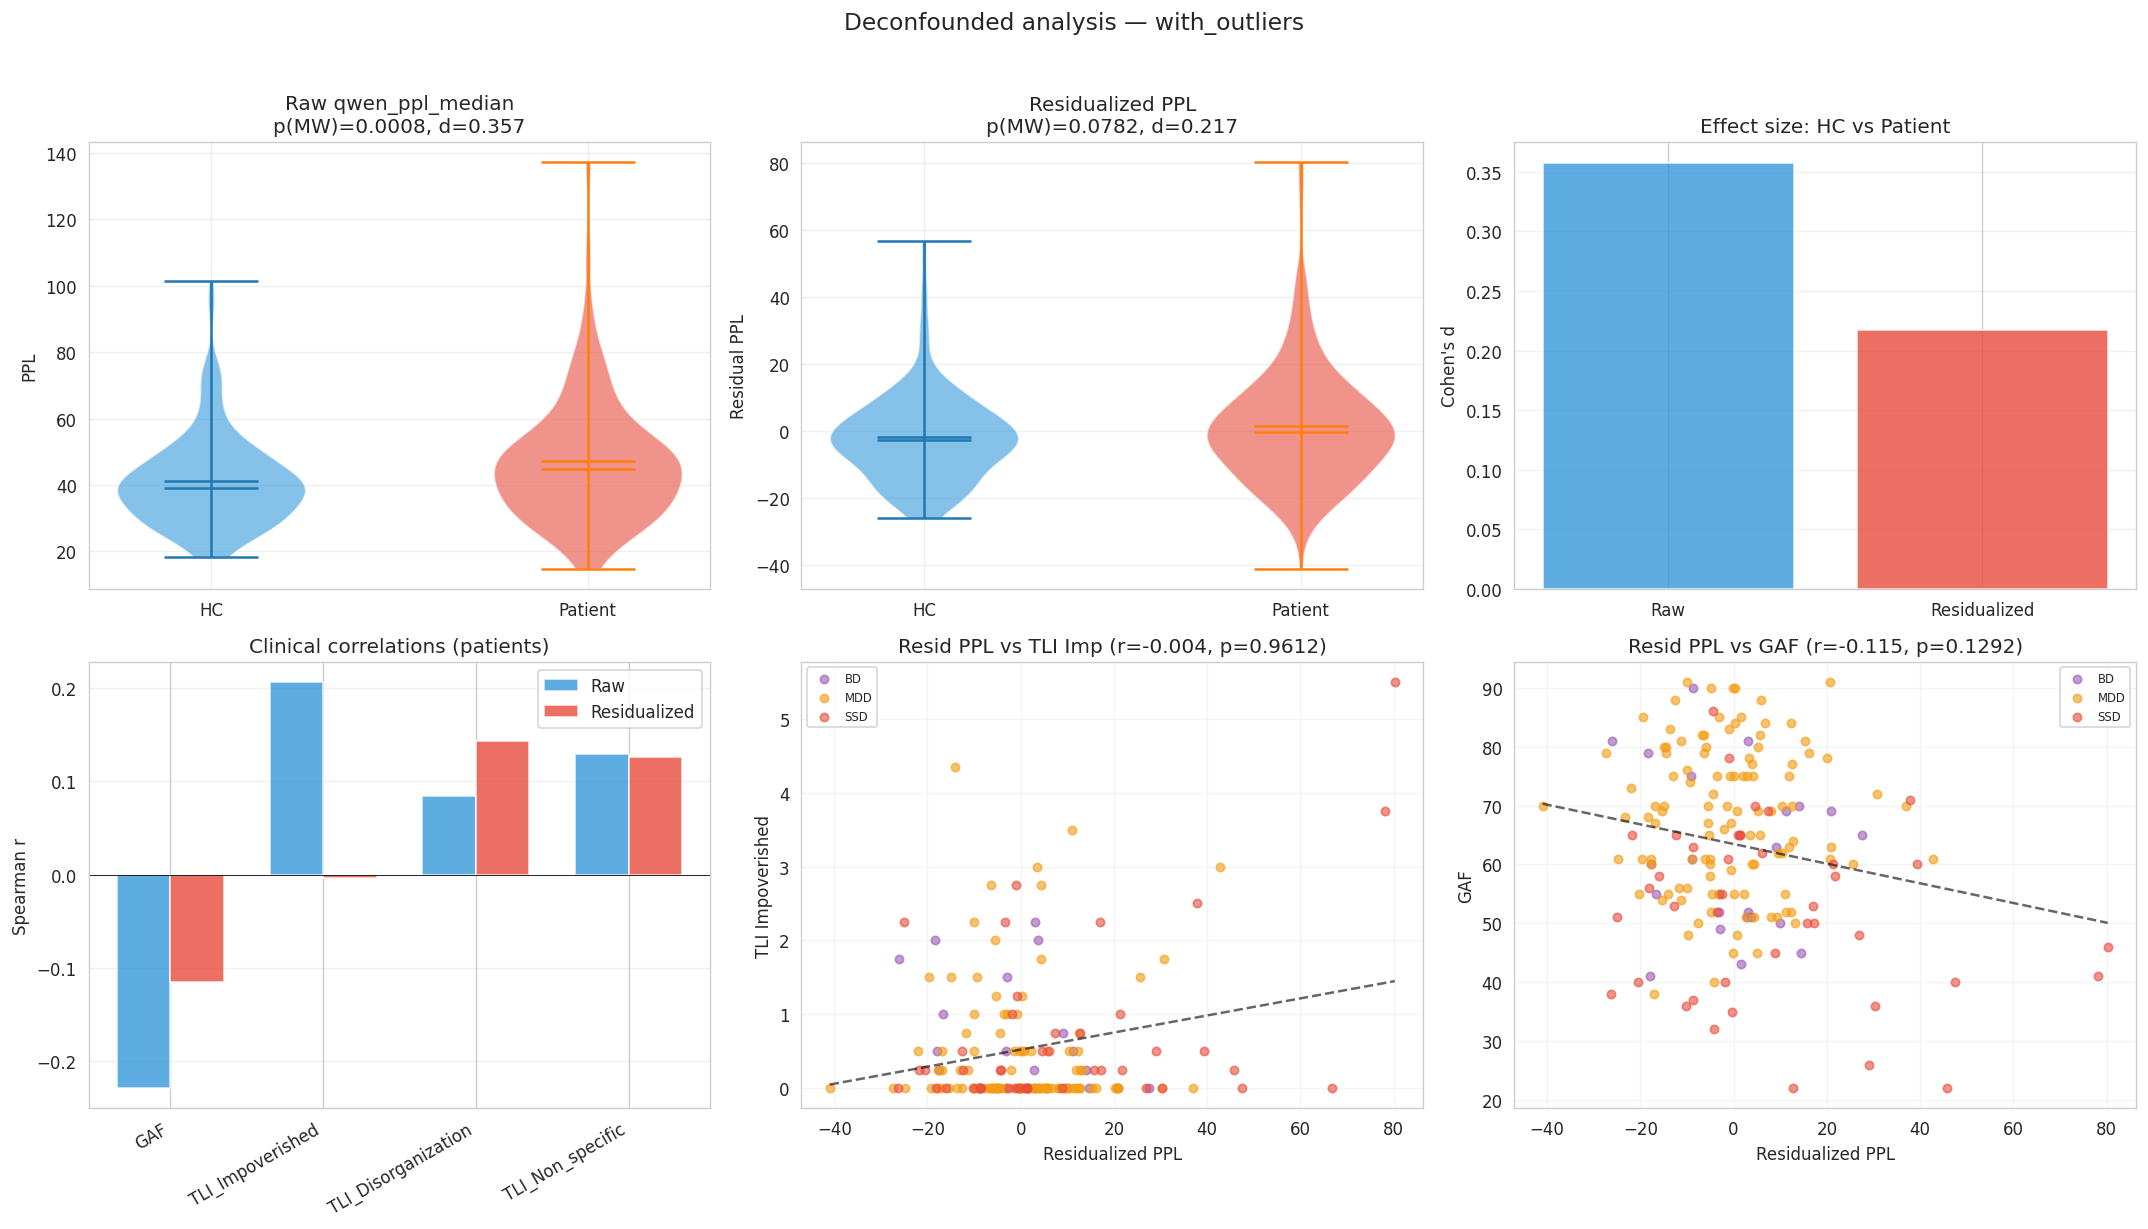


Setting: without_outliers | PPL variable: qwen_ppl_median_wins
Saved: figures/without_outliers/01_group_boxplot.png


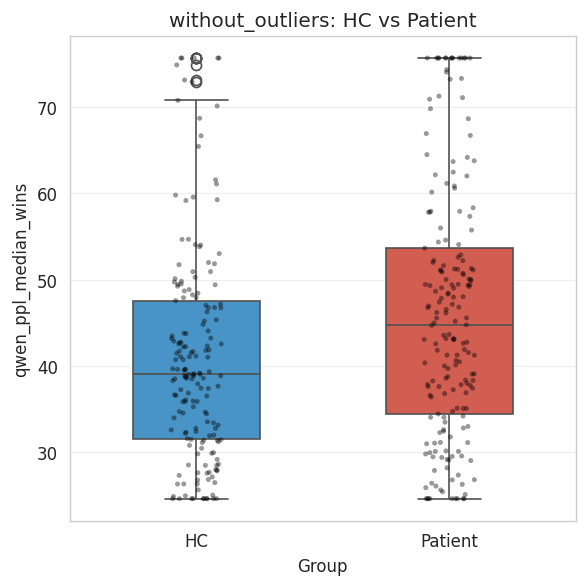


without_outliers — qwen_ppl_median_wins:
  Variable: qwen_ppl_median_wins
  Control (M±SD): 41.07±12.56
  Patient (M±SD): 46.09±14.77
  Control Median: 39.0090008613624
  Patient Median: 44.74777198748531
  t: 3.496231671018979
  p(t): 0.0005301770070495424
  U: 20120.0
  p(MW): 0.0007938268192305869
  Cohens d: 0.3656985261450754
  r: -0.20288165485905596

Clinical correlations (without_outliers):
  Clinical Variable         r        p   n
                GAF -0.227759 0.001930 183
   TLI_Impoverished  0.203967 0.006317 178
TLI_Disorganization  0.083088 0.270188 178
   TLI_Non_specific  0.127735 0.089288 178
Saved: figures/without_outliers/02_clinical_scatter.png


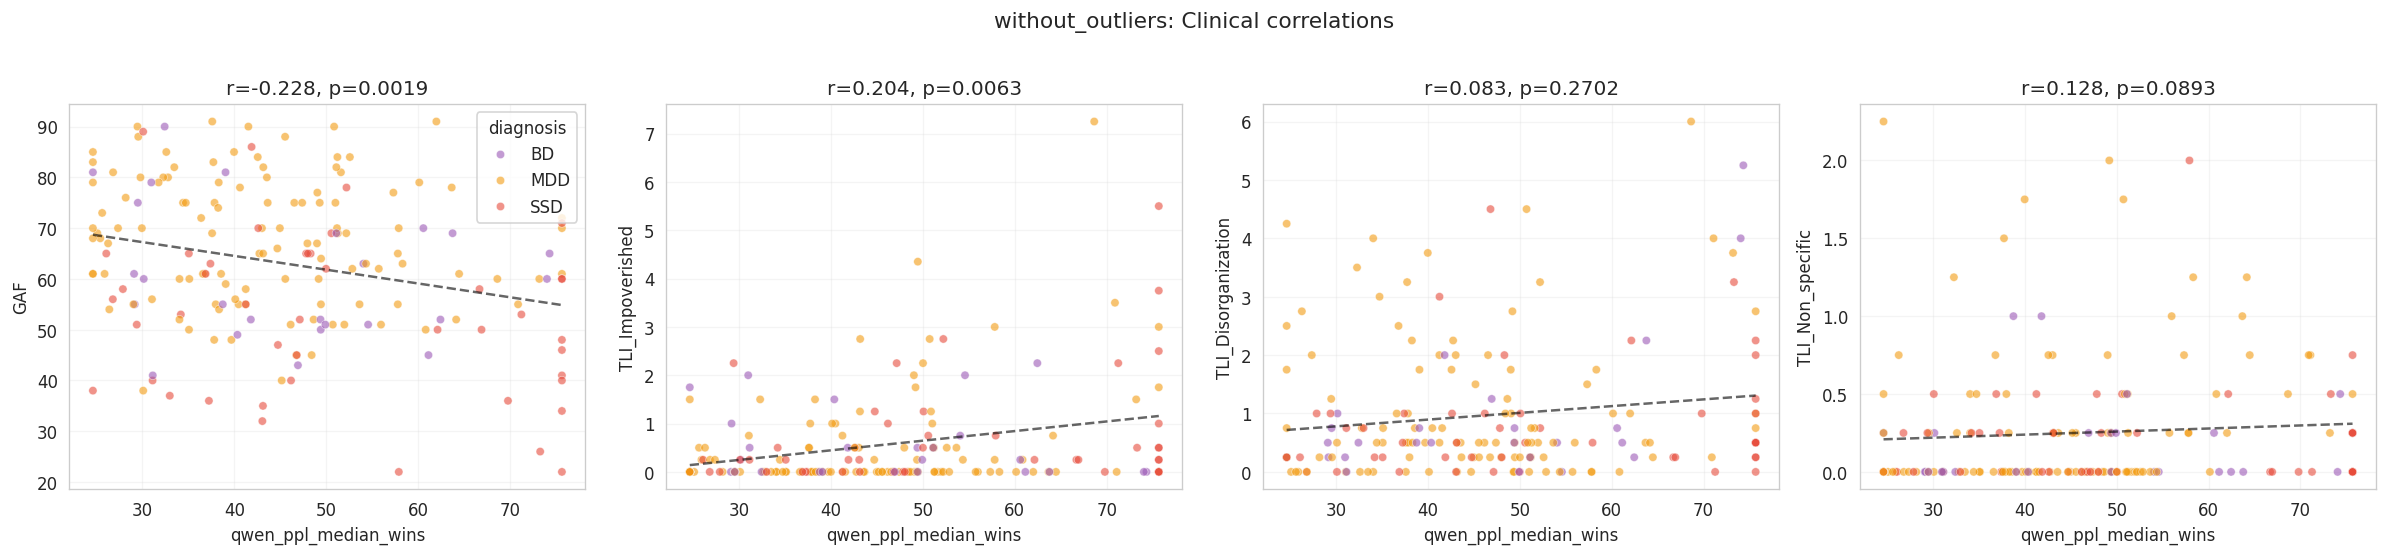

Saved: figures/without_outliers/03_diagnostic_groups.png


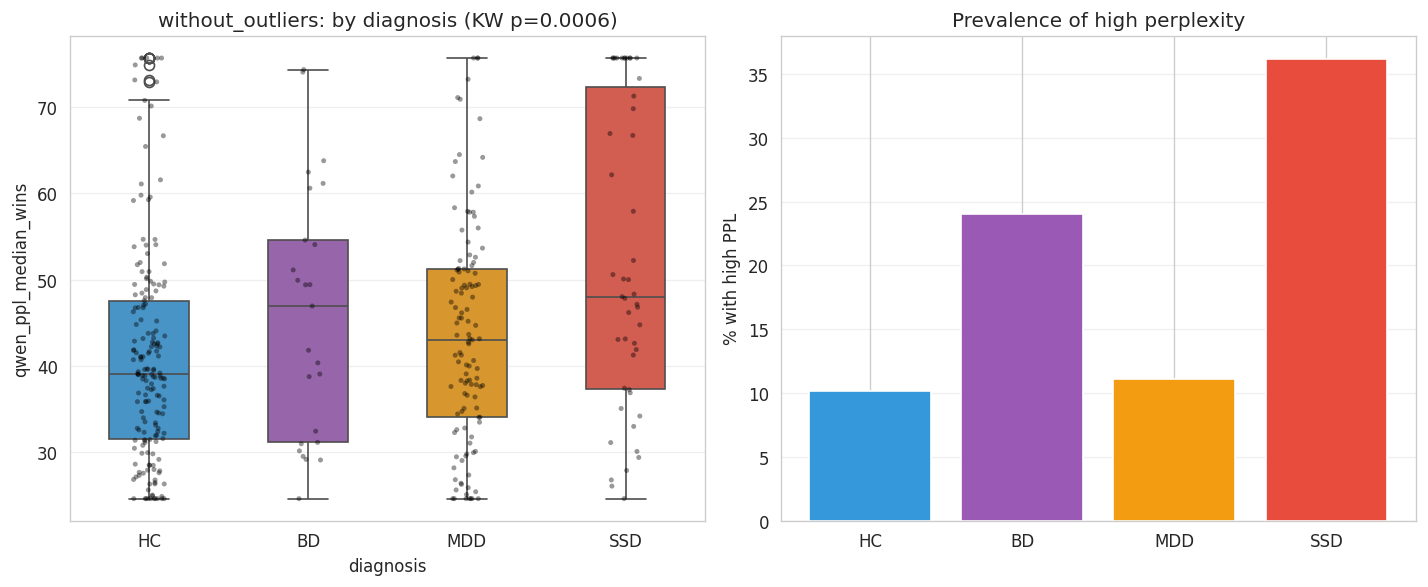

Saved: figures/without_outliers/04_extreme_groups.png


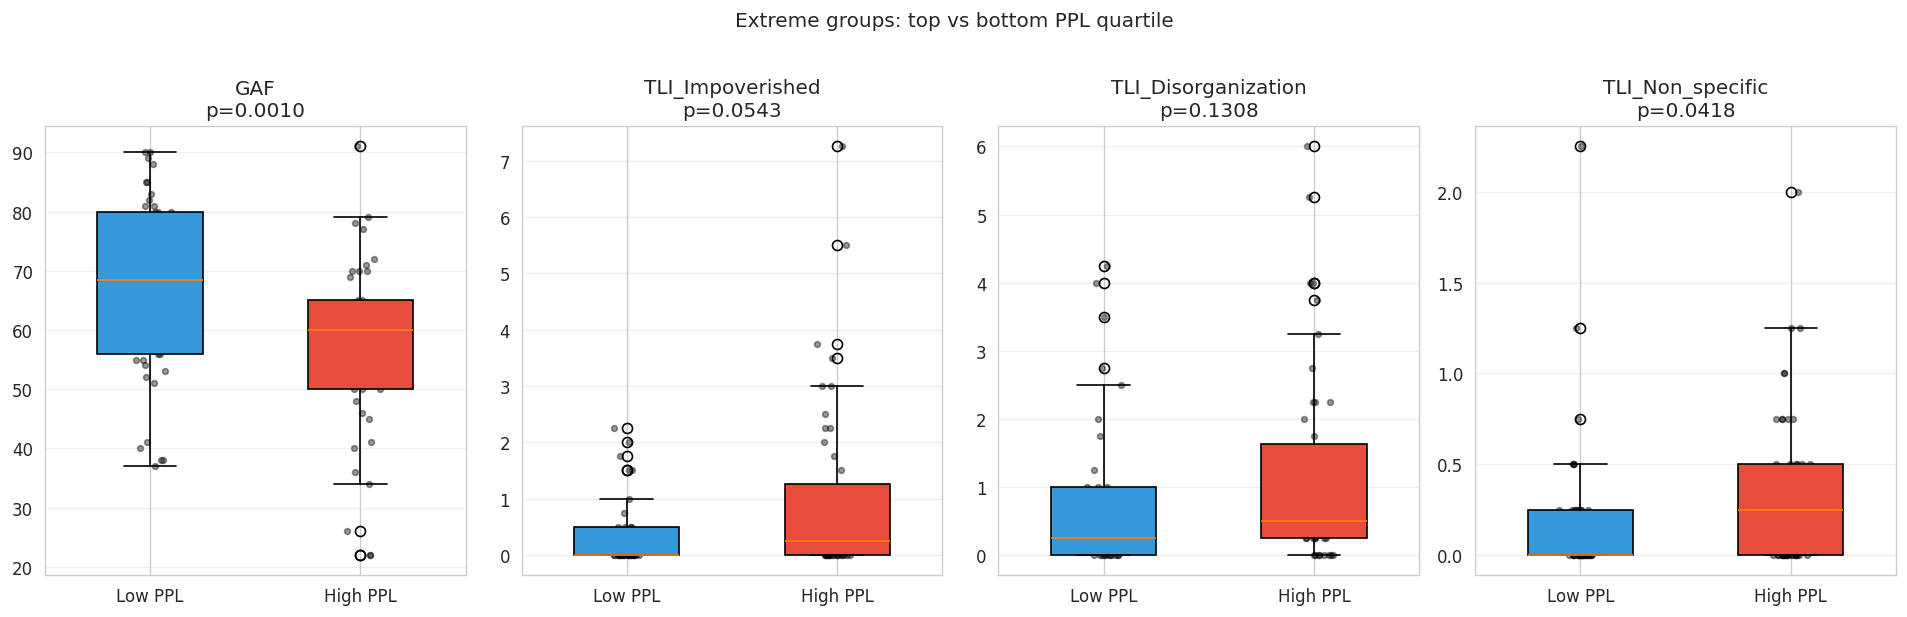

Saved: figures/without_outliers/05_tli_subscales.png


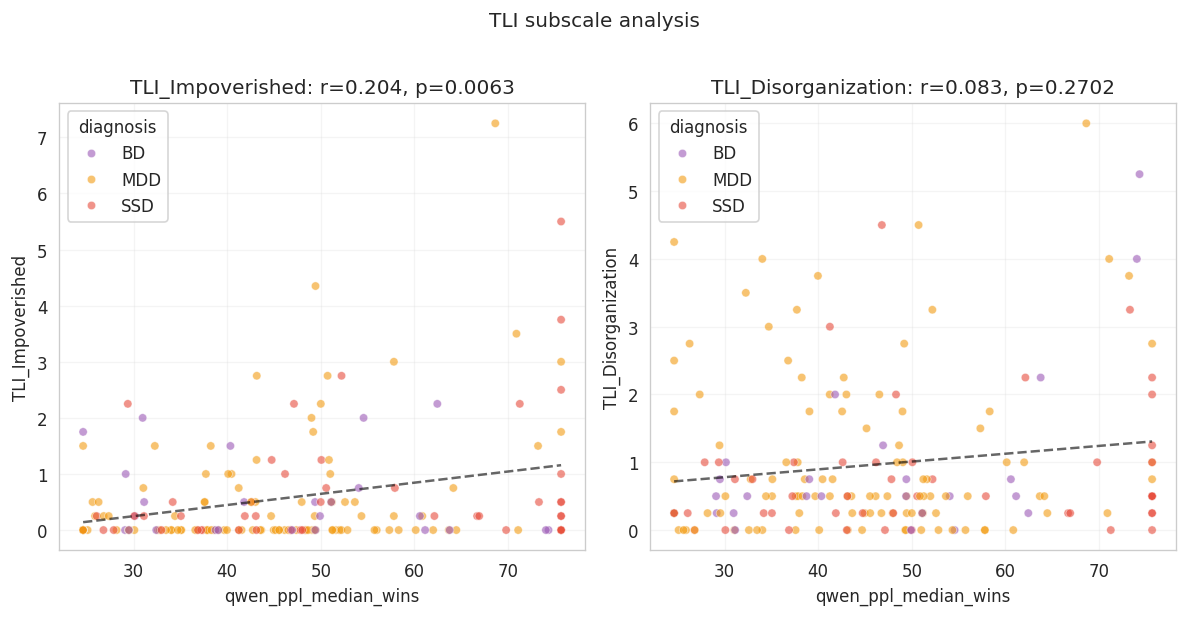


--- Deconfounding (without_outliers) ---
  Raw:          p(MW)=0.0008, d=0.366
  Residualized: p(MW)=0.0363, d=0.233

  Clinical correlations (raw vs residualized):
  Clinical Variable     r_raw    p_raw  n_raw   r_resid  p_resid  n_resid
                GAF -0.227759 0.001930    183 -0.123624 0.102123      176
   TLI_Impoverished  0.203967 0.006317    178  0.048912 0.526465      170
TLI_Disorganization  0.083088 0.270188    178  0.126786 0.099446      170
   TLI_Non_specific  0.127735 0.089288    178  0.139268 0.070099      170

  Kruskal-Wallis — Raw: H=17.507, p=0.0006
  Kruskal-Wallis — Resid: H=7.901, p=0.0481
Saved: figures/without_outliers/deconfounded/raw_vs_residualized.png


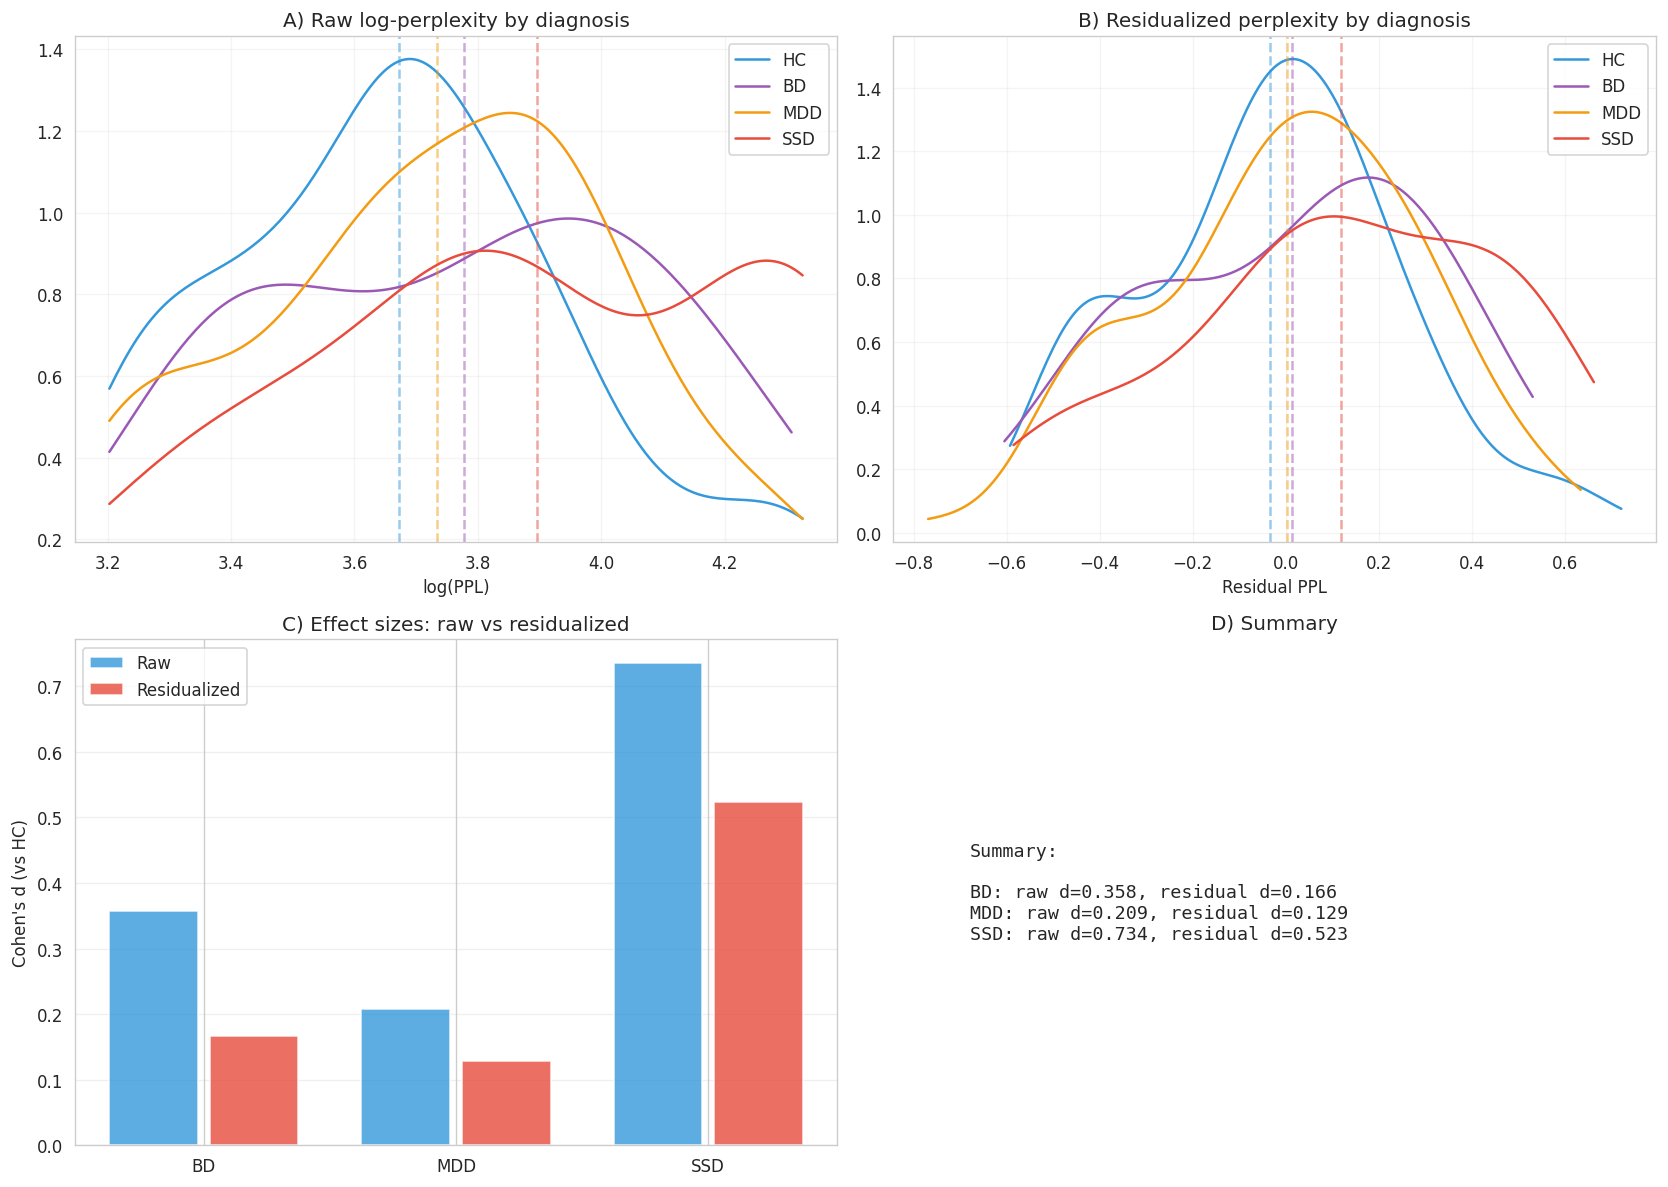

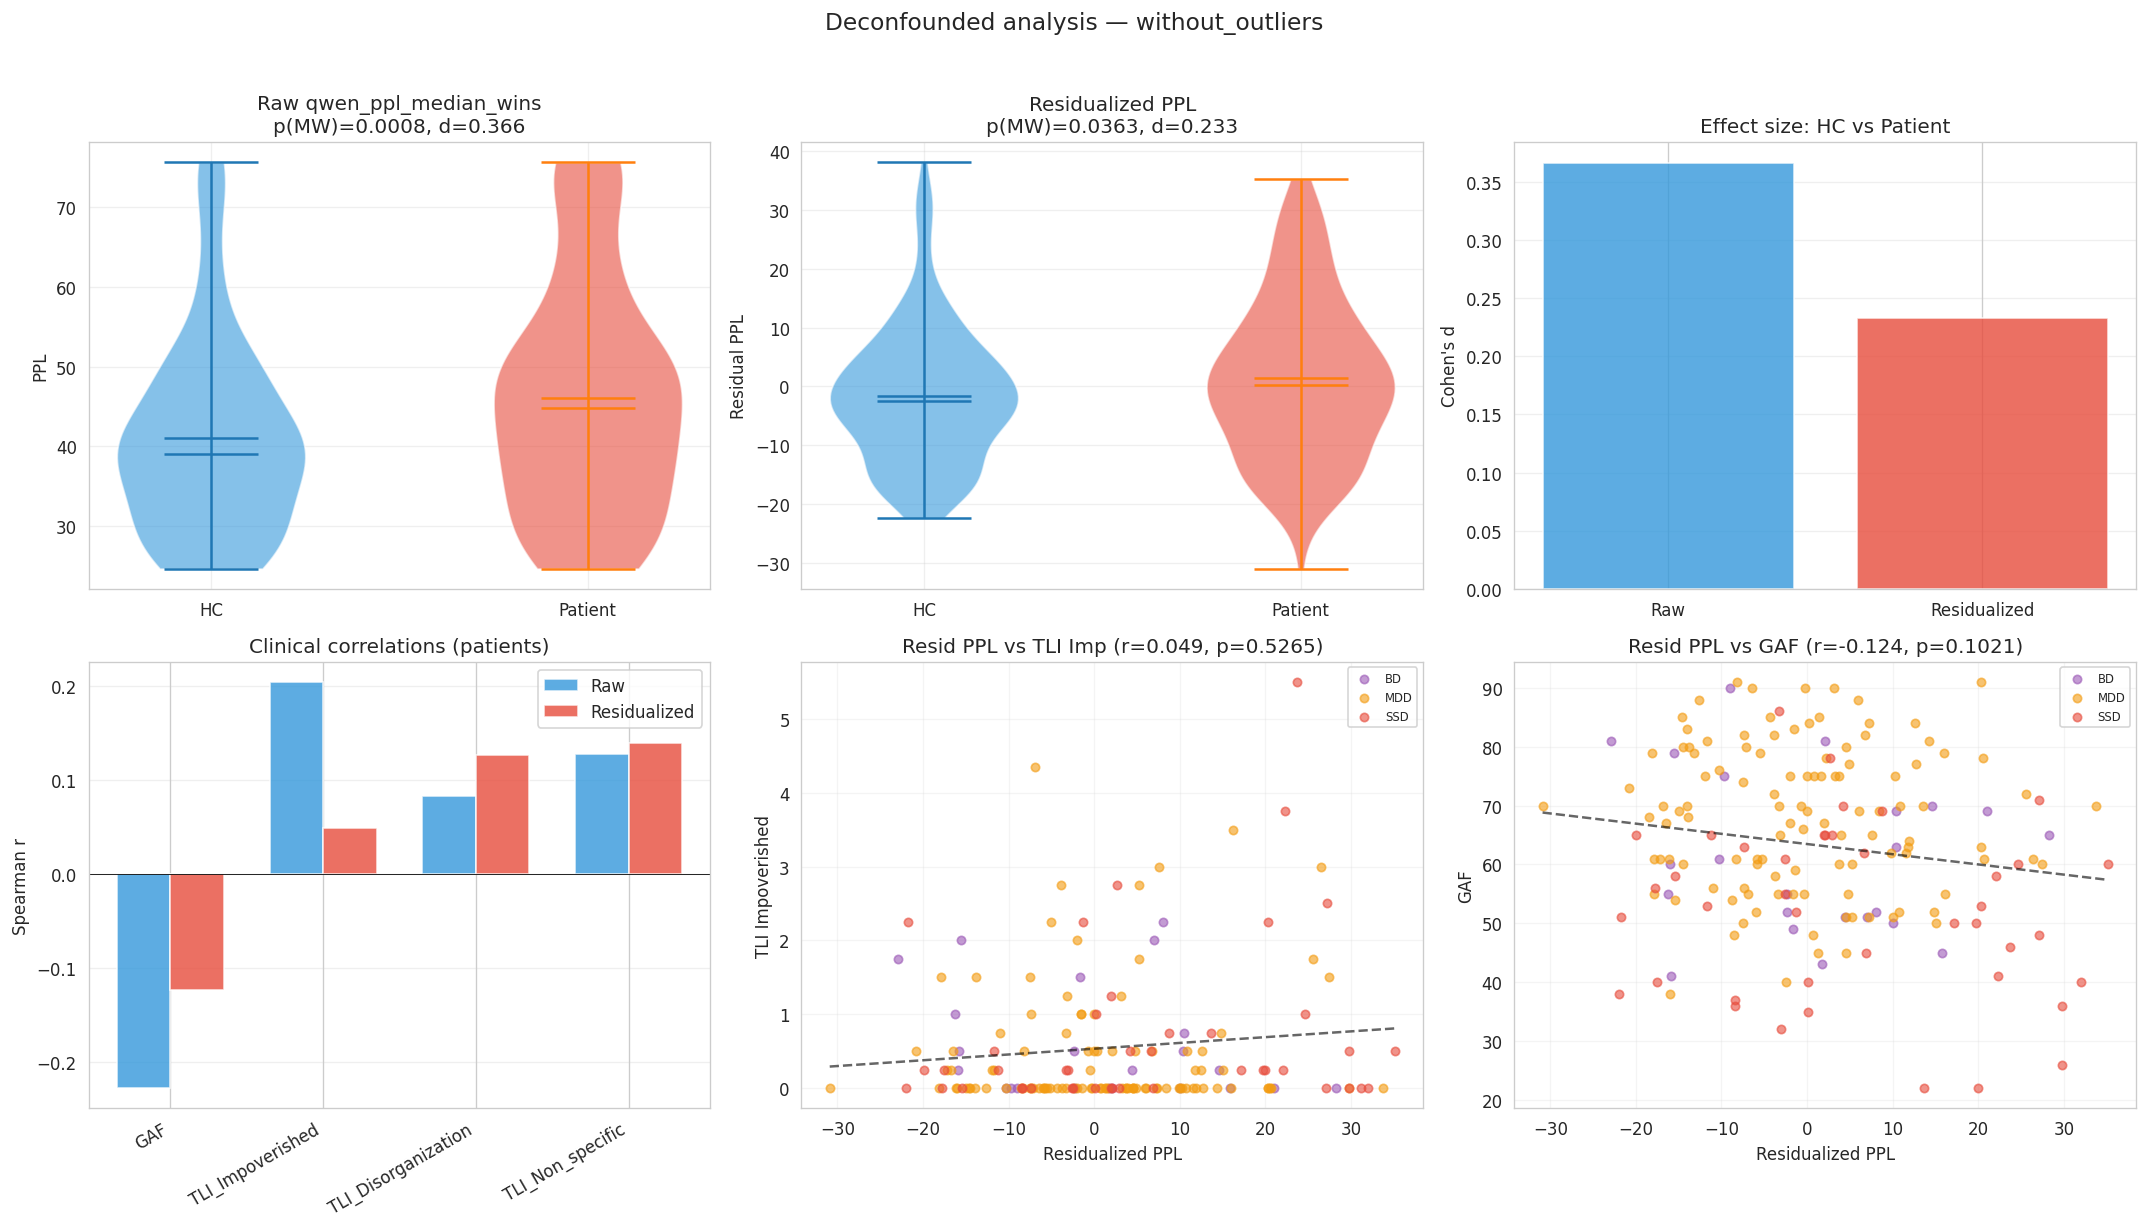


Setting: matched | PPL variable: qwen_ppl_median
Saved: figures/matched/01_group_boxplot.png


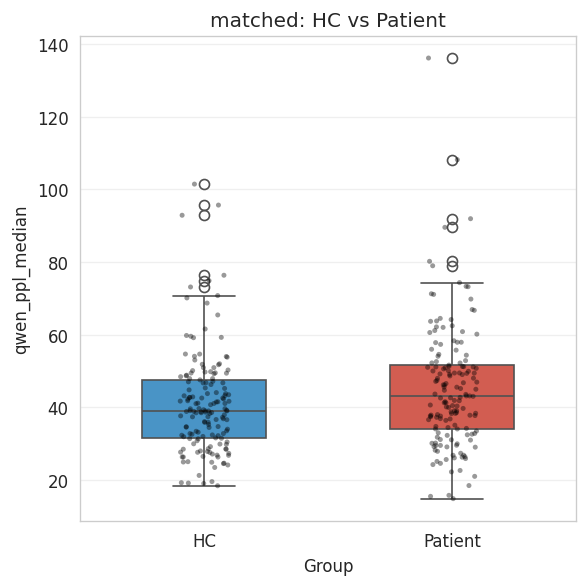


matched — qwen_ppl_median:
  Variable: qwen_ppl_median
  Control (M±SD): 41.01±14.03
  Patient (M±SD): 45.16±16.99
  Control Median: 39.0090008613624
  Patient Median: 43.00892423455211
  t: 2.3598030607044707
  p(t): 0.01890012398612202
  U: 14317.0
  p(MW): 0.013270573600104946
  Cohens d: 0.2663427819931958
  r: -0.16166984461844303

Clinical correlations (matched):
  Clinical Variable         r        p   n
                GAF -0.192266 0.016901 154
   TLI_Impoverished  0.178769 0.029711 148
TLI_Disorganization  0.045137 0.585936 148
   TLI_Non_specific  0.145215 0.078242 148
Saved: figures/matched/02_clinical_scatter.png


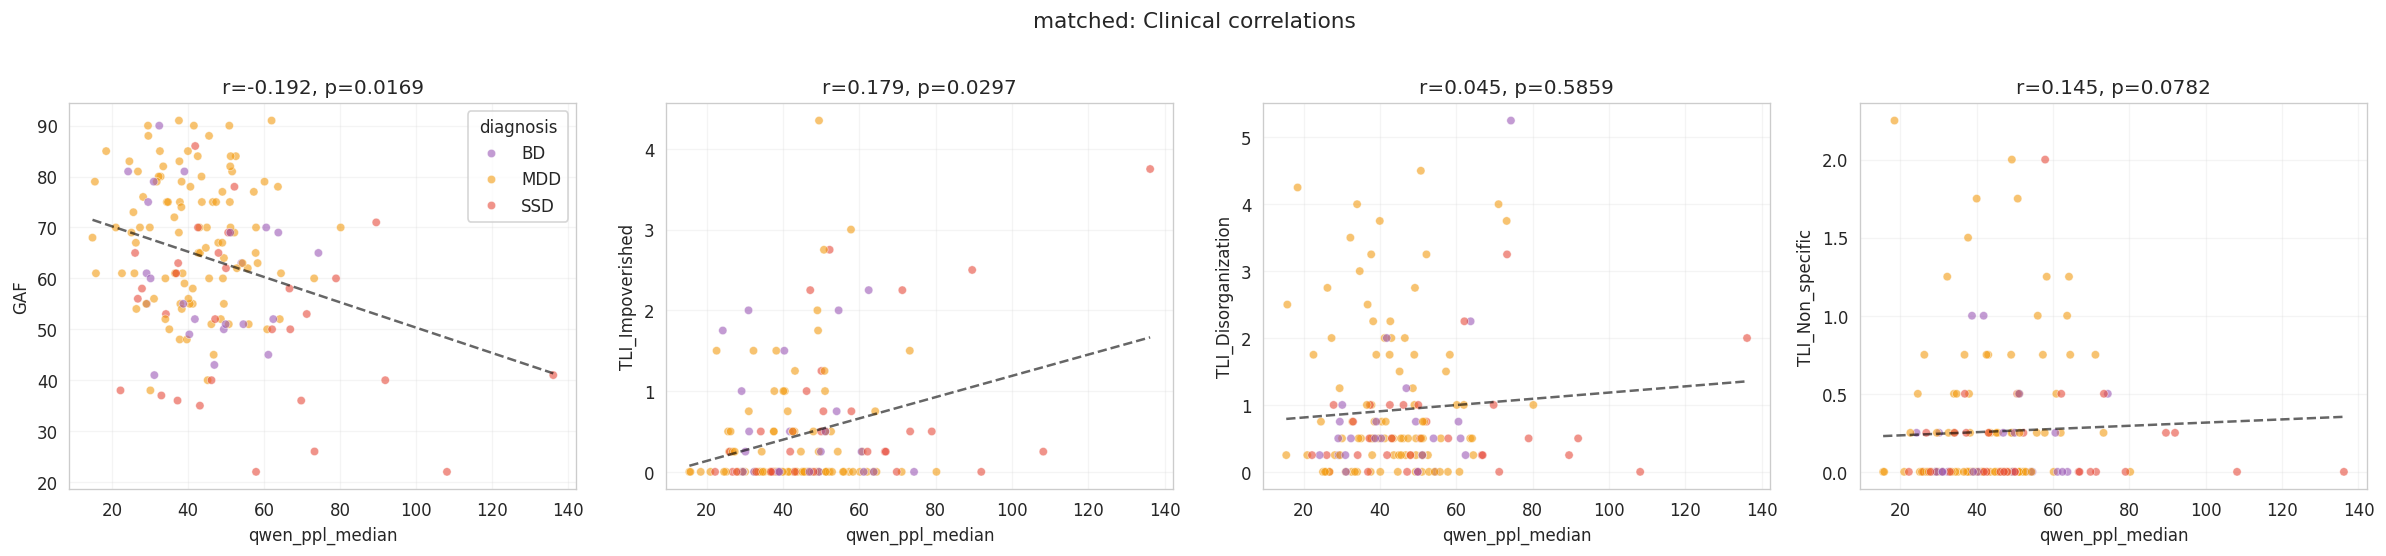

Saved: figures/matched/03_diagnostic_groups.png


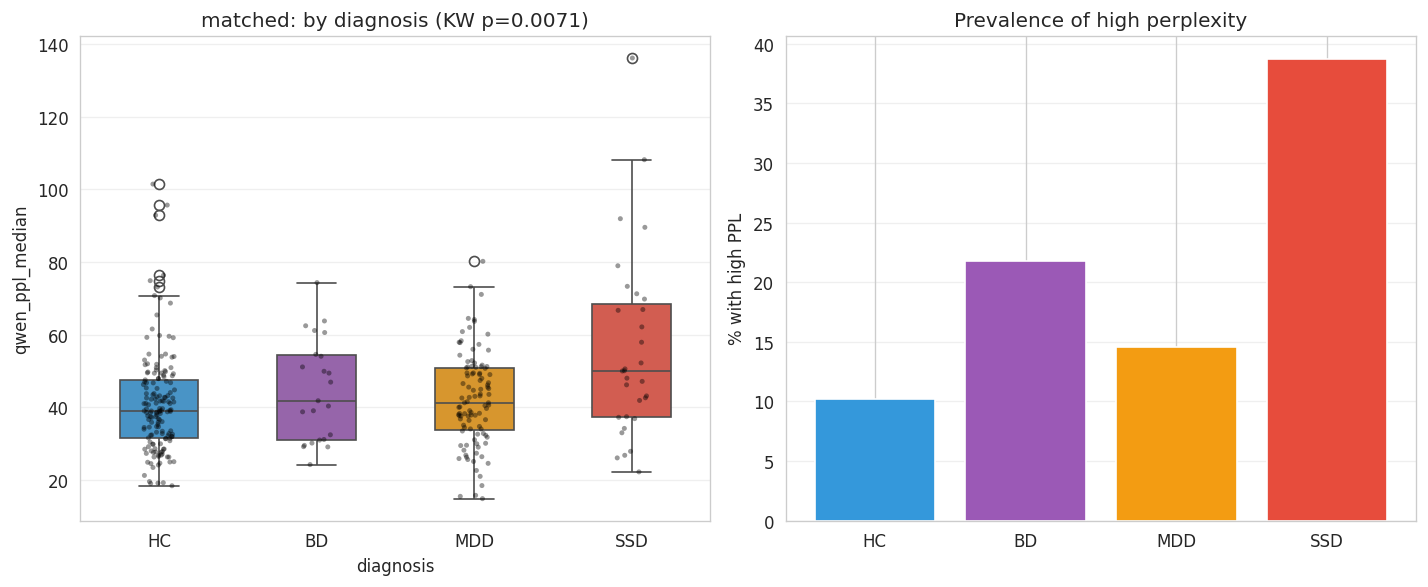

Saved: figures/matched/04_extreme_groups.png


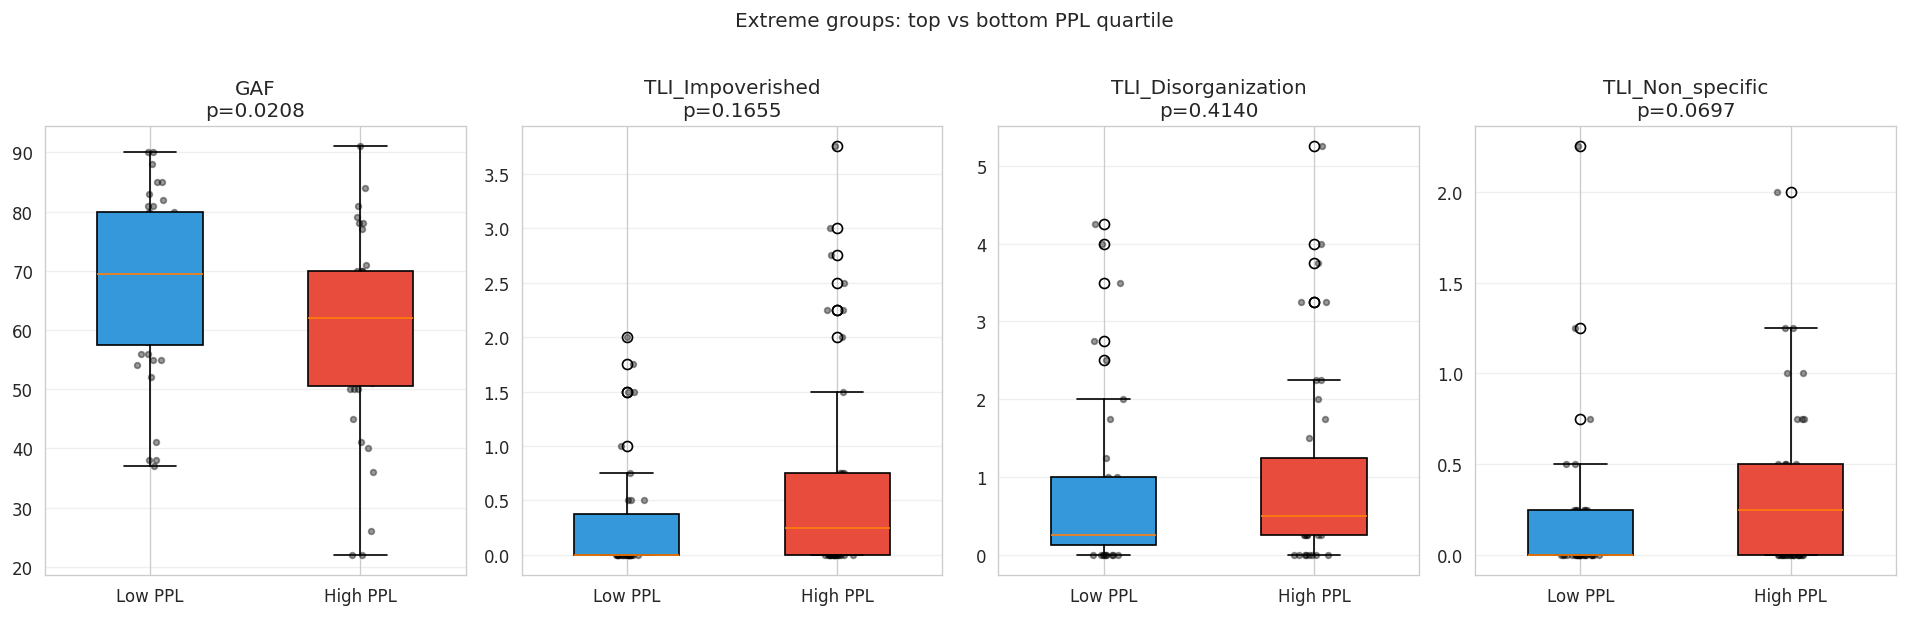

Saved: figures/matched/05_tli_subscales.png


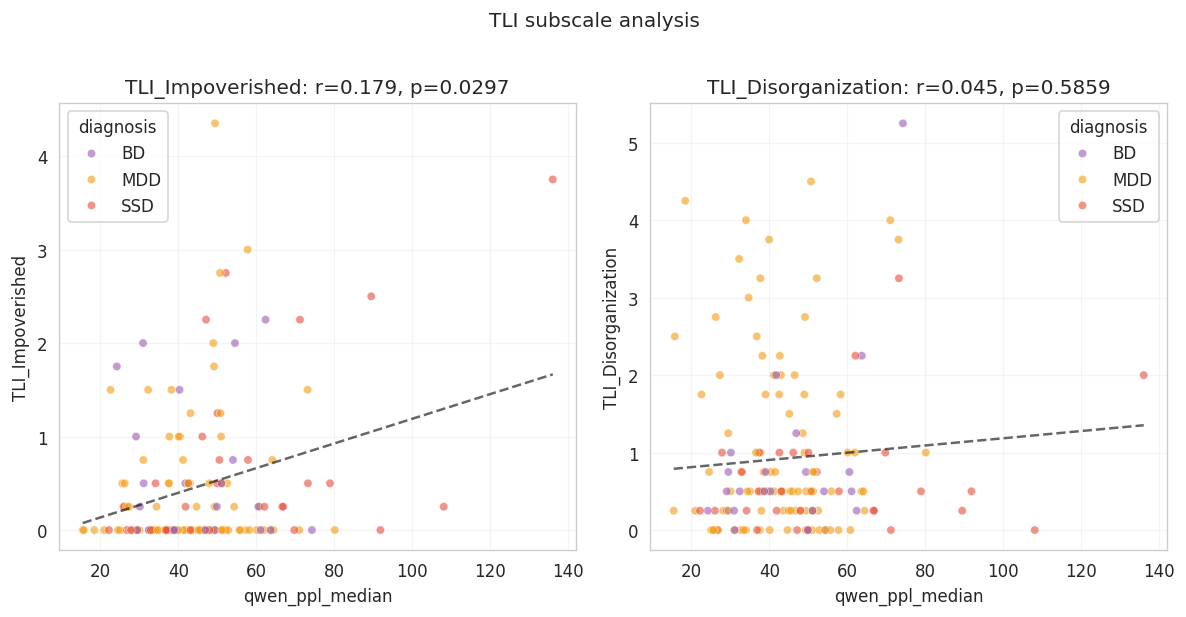


--- Deconfounding (matched) ---
  Raw:          p(MW)=0.0133, d=0.266
  Residualized: p(MW)=0.0499, d=0.204

  Clinical correlations (raw vs residualized):
  Clinical Variable     r_raw    p_raw  n_raw   r_resid  p_resid  n_resid
                GAF -0.192266 0.016901    154 -0.107994 0.182482      154
   TLI_Impoverished  0.178769 0.029711    148  0.011239 0.892156      148
TLI_Disorganization  0.045137 0.585936    148  0.094237 0.254595      148
   TLI_Non_specific  0.145215 0.078242    148  0.133879 0.104758      148

  Kruskal-Wallis — Raw: H=12.093, p=0.0071
  Kruskal-Wallis — Resid: H=7.742, p=0.0517
Saved: figures/matched/deconfounded/raw_vs_residualized.png


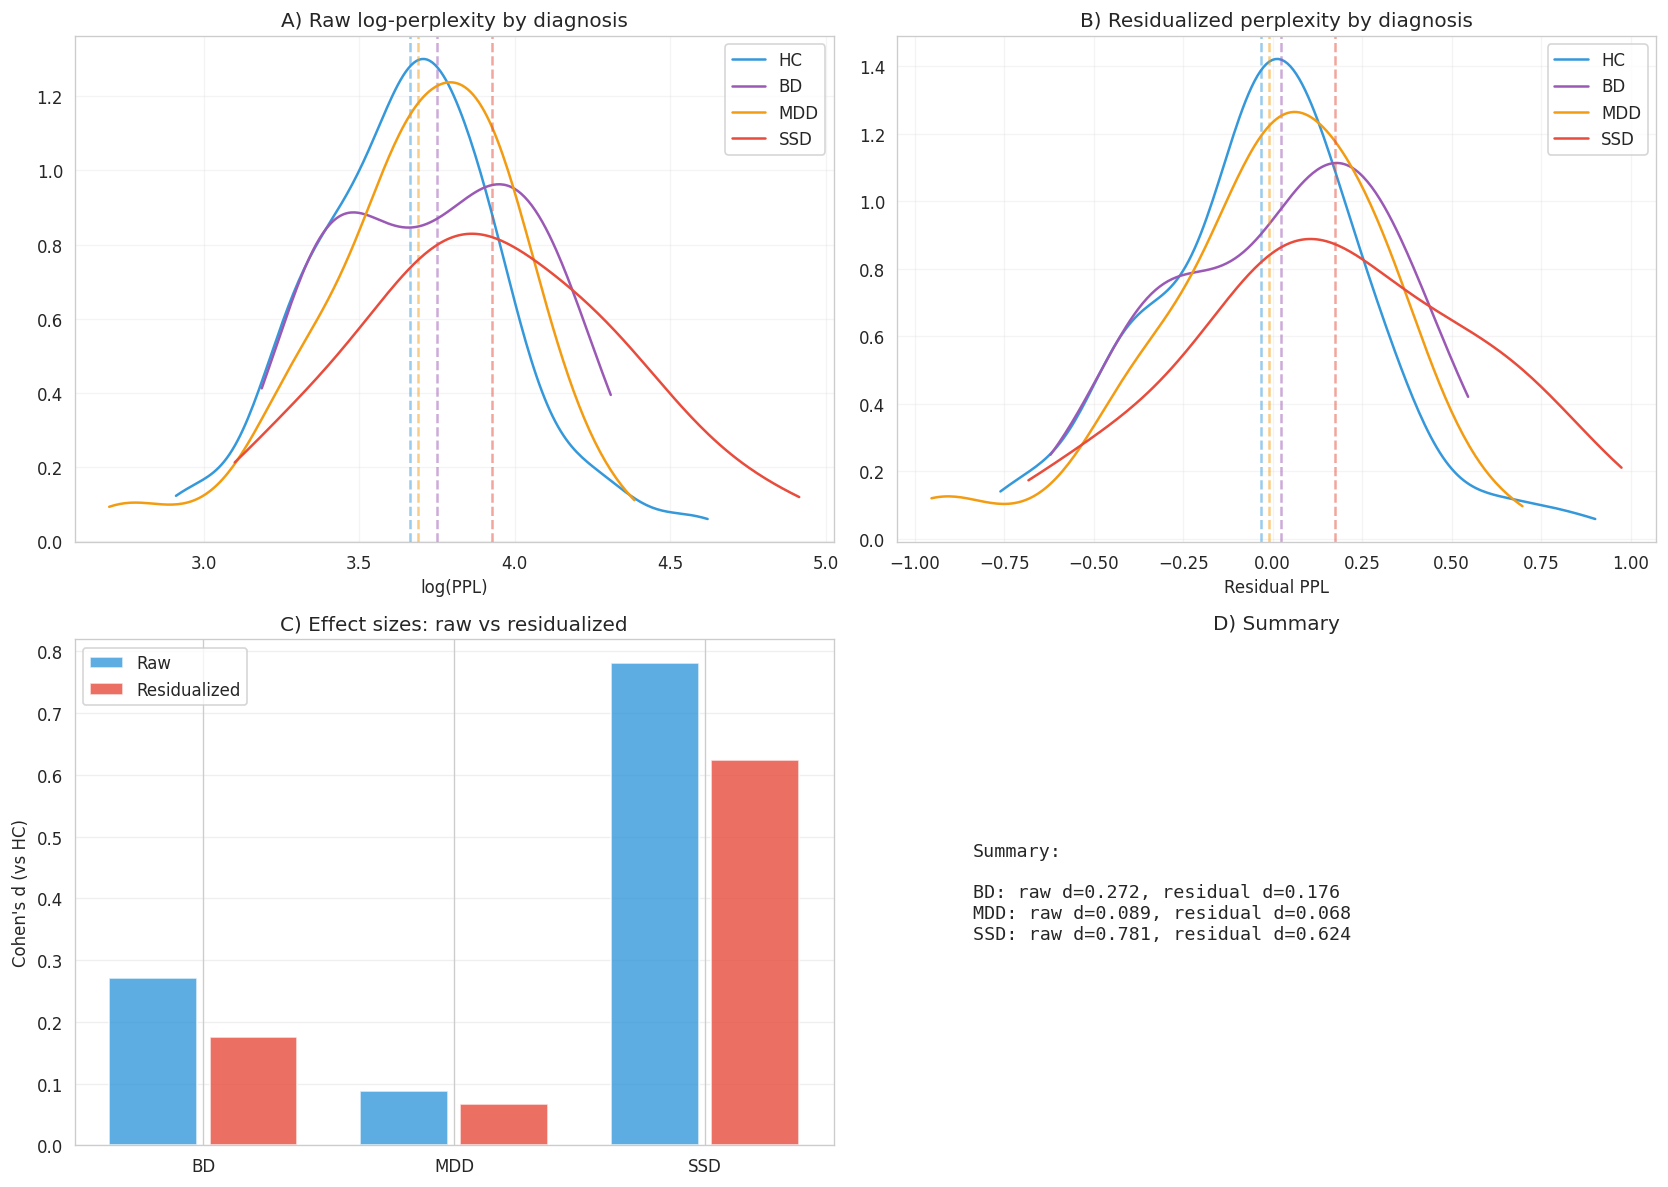

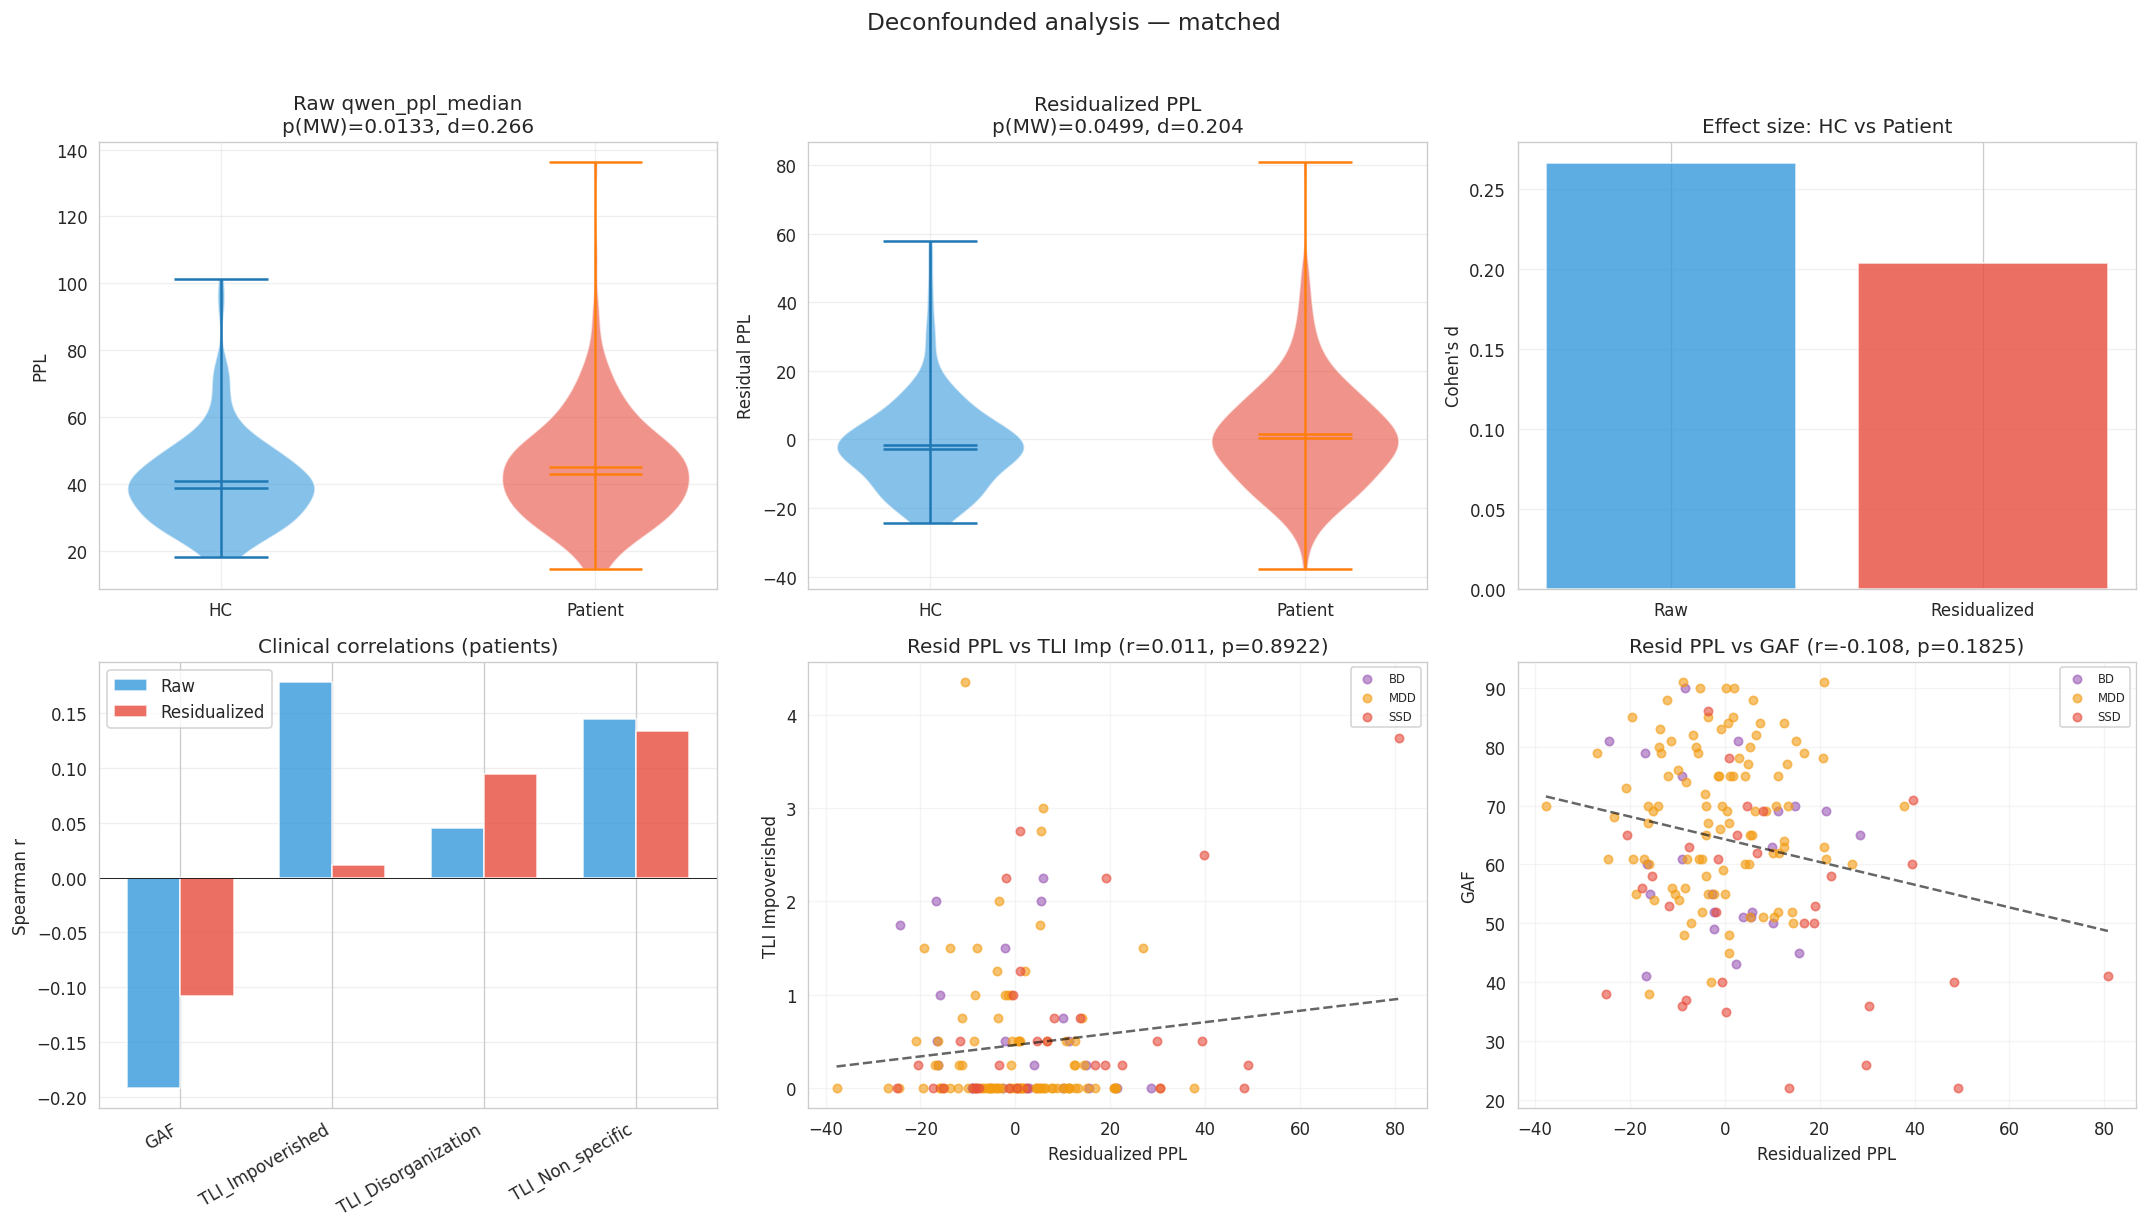

In [37]:
import statsmodels.api as sm

# Map each setting to the PPL variable it should use
setting_ppl_vars = {
    "with_outliers": PPL_VAR,
    "without_outliers": f"{PPL_VAR}_wins",
    "matched": PPL_VAR,
}

all_results = {}
all_corr_dfs = {}

for setting_name, setting_df in settings.items():
    ppl_col = setting_ppl_vars[setting_name]
    print(f"\n{'='*60}")
    print(f"Setting: {setting_name} | PPL variable: {ppl_col}")
    print(f"{'='*60}")

    # ── Standard analysis ─────────────────────────────────────────
    result = plot_setting(
        df=setting_df,
        ppl_var=ppl_col,
        setting_name=setting_name,
        figure_dir=FIGURE_DIR,
        clinical_vars=clinical_vars,
    )

    # ── Deconfounding analysis ────────────────────────────────────
    print(f"\n--- Deconfounding ({setting_name}) ---")
    sdf = setting_df.copy()
    sdf["log_words"] = np.log1p(sdf[WC_VAR])
    confounders = ["log_words"]
    if "education" in sdf.columns:
        confounders.append("education")

    resid = residualize_ppl(sdf, ppl_col, confounders)
    resid_col = f"{ppl_col}_resid"
    sdf[resid_col] = np.nan
    sdf.loc[resid.index, resid_col] = resid

    # Group comparison: raw vs residualized
    comp_raw = group_comparison(sdf, ppl_col)
    comp_resid = group_comparison(sdf.dropna(subset=[resid_col]), resid_col)
    print(f"  Raw:          p(MW)={comp_raw['p(MW)']:.4f}, d={comp_raw['Cohens d']:.3f}")
    print(f"  Residualized: p(MW)={comp_resid['p(MW)']:.4f}, d={comp_resid['Cohens d']:.3f}")

    # Clinical correlations: raw vs residualized
    patients_s = sdf[sdf["is_patient"] == 1].copy()
    corr_raw = clinical_correlations(patients_s, ppl_col, clinical_vars)
    corr_resid = clinical_correlations(
        patients_s.dropna(subset=[resid_col]), resid_col, clinical_vars
    )
    merged_corr = corr_raw.merge(
        corr_resid, on="Clinical Variable", suffixes=("_raw", "_resid")
    )
    print(f"\n  Clinical correlations (raw vs residualized):")
    print(merged_corr.to_string(index=False))

    # Pairwise vs HC: raw vs residualized
    from functions.analysis.statistics import pairwise_vs_hc, kruskal_wallis_test
    pw_raw = pairwise_vs_hc(sdf, ppl_col)
    pw_resid = pairwise_vs_hc(sdf.dropna(subset=[resid_col]), resid_col)
    kw_raw_stat, kw_raw_p = kruskal_wallis_test(sdf, ppl_col)
    kw_res_stat, kw_res_p = kruskal_wallis_test(
        sdf.dropna(subset=[resid_col]), resid_col
    )
    print(f"\n  Kruskal-Wallis — Raw: H={kw_raw_stat:.3f}, p={kw_raw_p:.4f}")
    print(f"  Kruskal-Wallis — Resid: H={kw_res_stat:.3f}, p={kw_res_p:.4f}")

    # ── Deconfounded visualisation ────────────────────────────────
    deconf_dir = os.path.join(FIGURE_DIR, setting_name, "deconfounded")
    os.makedirs(deconf_dir, exist_ok=True)

    # Plot 1: raw vs residualized (uses plotting_service helper)
    plot_raw_vs_residualized(
        sdf, ppl_col, WC_VAR,
        save_path=os.path.join(deconf_dir, "raw_vs_residualized.png"),
    )

    # Plot 2: deconfounded comparison figure
    from functions.plotting.plots import DIAG_ORDER, DIAG_COLORS
    from scipy.stats import spearmanr as _spearmanr

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))

    # Row 1 col 0: Raw PPL violin
    ax = axes[0, 0]
    for is_pat, lbl, clr in [(0, "HC", "#3498DB"), (1, "Patient", "#E74C3C")]:
        vals = sdf[sdf["is_patient"] == is_pat][ppl_col].dropna()
        parts = ax.violinplot([vals], positions=[is_pat], showmeans=True, showmedians=True)
        for pc in parts["bodies"]:
            pc.set_facecolor(clr); pc.set_alpha(0.6)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["HC", "Patient"])
    ax.set_title(f"Raw {ppl_col}\np(MW)={comp_raw['p(MW)']:.4f}, d={comp_raw['Cohens d']:.3f}")
    ax.set_ylabel("PPL"); ax.grid(alpha=0.3)

    # Row 1 col 1: Residualized PPL violin
    ax = axes[0, 1]
    for is_pat, lbl, clr in [(0, "HC", "#3498DB"), (1, "Patient", "#E74C3C")]:
        vals = sdf[sdf["is_patient"] == is_pat][resid_col].dropna()
        parts = ax.violinplot([vals], positions=[is_pat], showmeans=True, showmedians=True)
        for pc in parts["bodies"]:
            pc.set_facecolor(clr); pc.set_alpha(0.6)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["HC", "Patient"])
    ax.set_title(f"Residualized PPL\np(MW)={comp_resid['p(MW)']:.4f}, d={comp_resid['Cohens d']:.3f}")
    ax.set_ylabel("Residual PPL"); ax.grid(alpha=0.3)

    # Row 1 col 2: Cohen's d comparison
    ax = axes[0, 2]
    ax.bar(["Raw", "Residualized"], [comp_raw["Cohens d"], comp_resid["Cohens d"]],
           color=["#3498DB", "#E74C3C"], alpha=0.8)
    ax.set_ylabel("Cohen's d"); ax.set_title("Effect size: HC vs Patient")
    ax.grid(axis="y", alpha=0.3); ax.axhline(0, color="black", lw=0.5)

    # Row 2 col 0: Clinical correlations bar chart
    ax = axes[1, 0]
    x = np.arange(len(clinical_vars))
    w = 0.35
    bars_raw = merged_corr.set_index("Clinical Variable").reindex(clinical_vars)["r_raw"]
    bars_res = merged_corr.set_index("Clinical Variable").reindex(clinical_vars)["r_resid"]
    ax.bar(x - w/2, bars_raw, w, label="Raw", color="#3498DB", alpha=0.8)
    ax.bar(x + w/2, bars_res, w, label="Residualized", color="#E74C3C", alpha=0.8)
    ax.set_xticks(x); ax.set_xticklabels(clinical_vars, rotation=30, ha="right")
    ax.set_ylabel("Spearman r"); ax.set_title("Clinical correlations (patients)")
    ax.legend(); ax.axhline(0, color="black", lw=0.5); ax.grid(axis="y", alpha=0.3)

    # Row 2 col 1: Scatter — residualized PPL vs TLI Impoverished
    ax = axes[1, 1]
    sub = patients_s[[resid_col, "TLI_Impoverished", "diagnosis"]].dropna()
    if len(sub) >= 5:
        diags = [d for d in DIAG_ORDER if d in sub["diagnosis"].values]
        for dx in diags:
            s = sub[sub["diagnosis"] == dx]
            ax.scatter(s[resid_col], s["TLI_Impoverished"], color=DIAG_COLORS.get(dx, "#888"),
                       label=dx, alpha=0.6, s=25)
        r, p = _spearmanr(sub[resid_col], sub["TLI_Impoverished"])
        z = np.polyfit(sub[resid_col], sub["TLI_Impoverished"], 1)
        xs = np.linspace(sub[resid_col].min(), sub[resid_col].max(), 100)
        ax.plot(xs, np.polyval(z, xs), "k--", alpha=0.6)
        ax.set_xlabel("Residualized PPL"); ax.set_ylabel("TLI Impoverished")
        ax.set_title(f"Resid PPL vs TLI Imp (r={r:.3f}, p={p:.4f})")
        ax.legend(fontsize=7); ax.grid(alpha=0.2)

    # Row 2 col 2: Scatter — residualized PPL vs GAF
    ax = axes[1, 2]
    sub = patients_s[[resid_col, "GAF", "diagnosis"]].dropna()
    if len(sub) >= 5:
        diags = [d for d in DIAG_ORDER if d in sub["diagnosis"].values]
        for dx in diags:
            s = sub[sub["diagnosis"] == dx]
            ax.scatter(s[resid_col], s["GAF"], color=DIAG_COLORS.get(dx, "#888"),
                       label=dx, alpha=0.6, s=25)
        r, p = _spearmanr(sub[resid_col], sub["GAF"])
        z = np.polyfit(sub[resid_col], sub["GAF"], 1)
        xs = np.linspace(sub[resid_col].min(), sub[resid_col].max(), 100)
        ax.plot(xs, np.polyval(z, xs), "k--", alpha=0.6)
        ax.set_xlabel("Residualized PPL"); ax.set_ylabel("GAF")
        ax.set_title(f"Resid PPL vs GAF (r={r:.3f}, p={p:.4f})")
        ax.legend(fontsize=7); ax.grid(alpha=0.2)

    fig.suptitle(f"Deconfounded analysis — {setting_name}", fontsize=14, y=1.02)
    fig.tight_layout()
    fig.savefig(os.path.join(deconf_dir, "deconfounded_analysis.png"),
                dpi=150, bbox_inches="tight")
    plt.show()

    # ── Store results ─────────────────────────────────────────────
    result["deconfounded"] = {
        "comparison_raw": comp_raw,
        "comparison_resid": comp_resid,
        "correlations_raw": corr_raw,
        "correlations_resid": corr_resid,
        "merged_correlations": merged_corr,
        "pairwise_raw": pw_raw,
        "pairwise_resid": pw_resid,
        "kruskal_raw": (kw_raw_stat, kw_raw_p),
        "kruskal_resid": (kw_res_stat, kw_res_p),
    }
    all_results[setting_name] = result
    all_corr_dfs[setting_name] = result["correlations"]

## 4. Cross-setting comparison

Saved: figures/cross_setting/robustness_bar.png


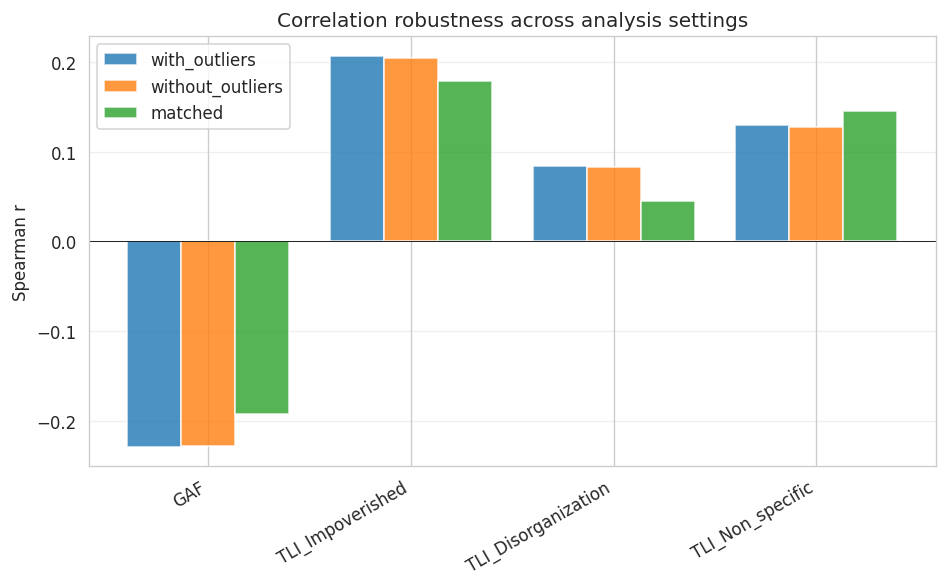

Saved: figures/cross_setting/robustness_scatter.png


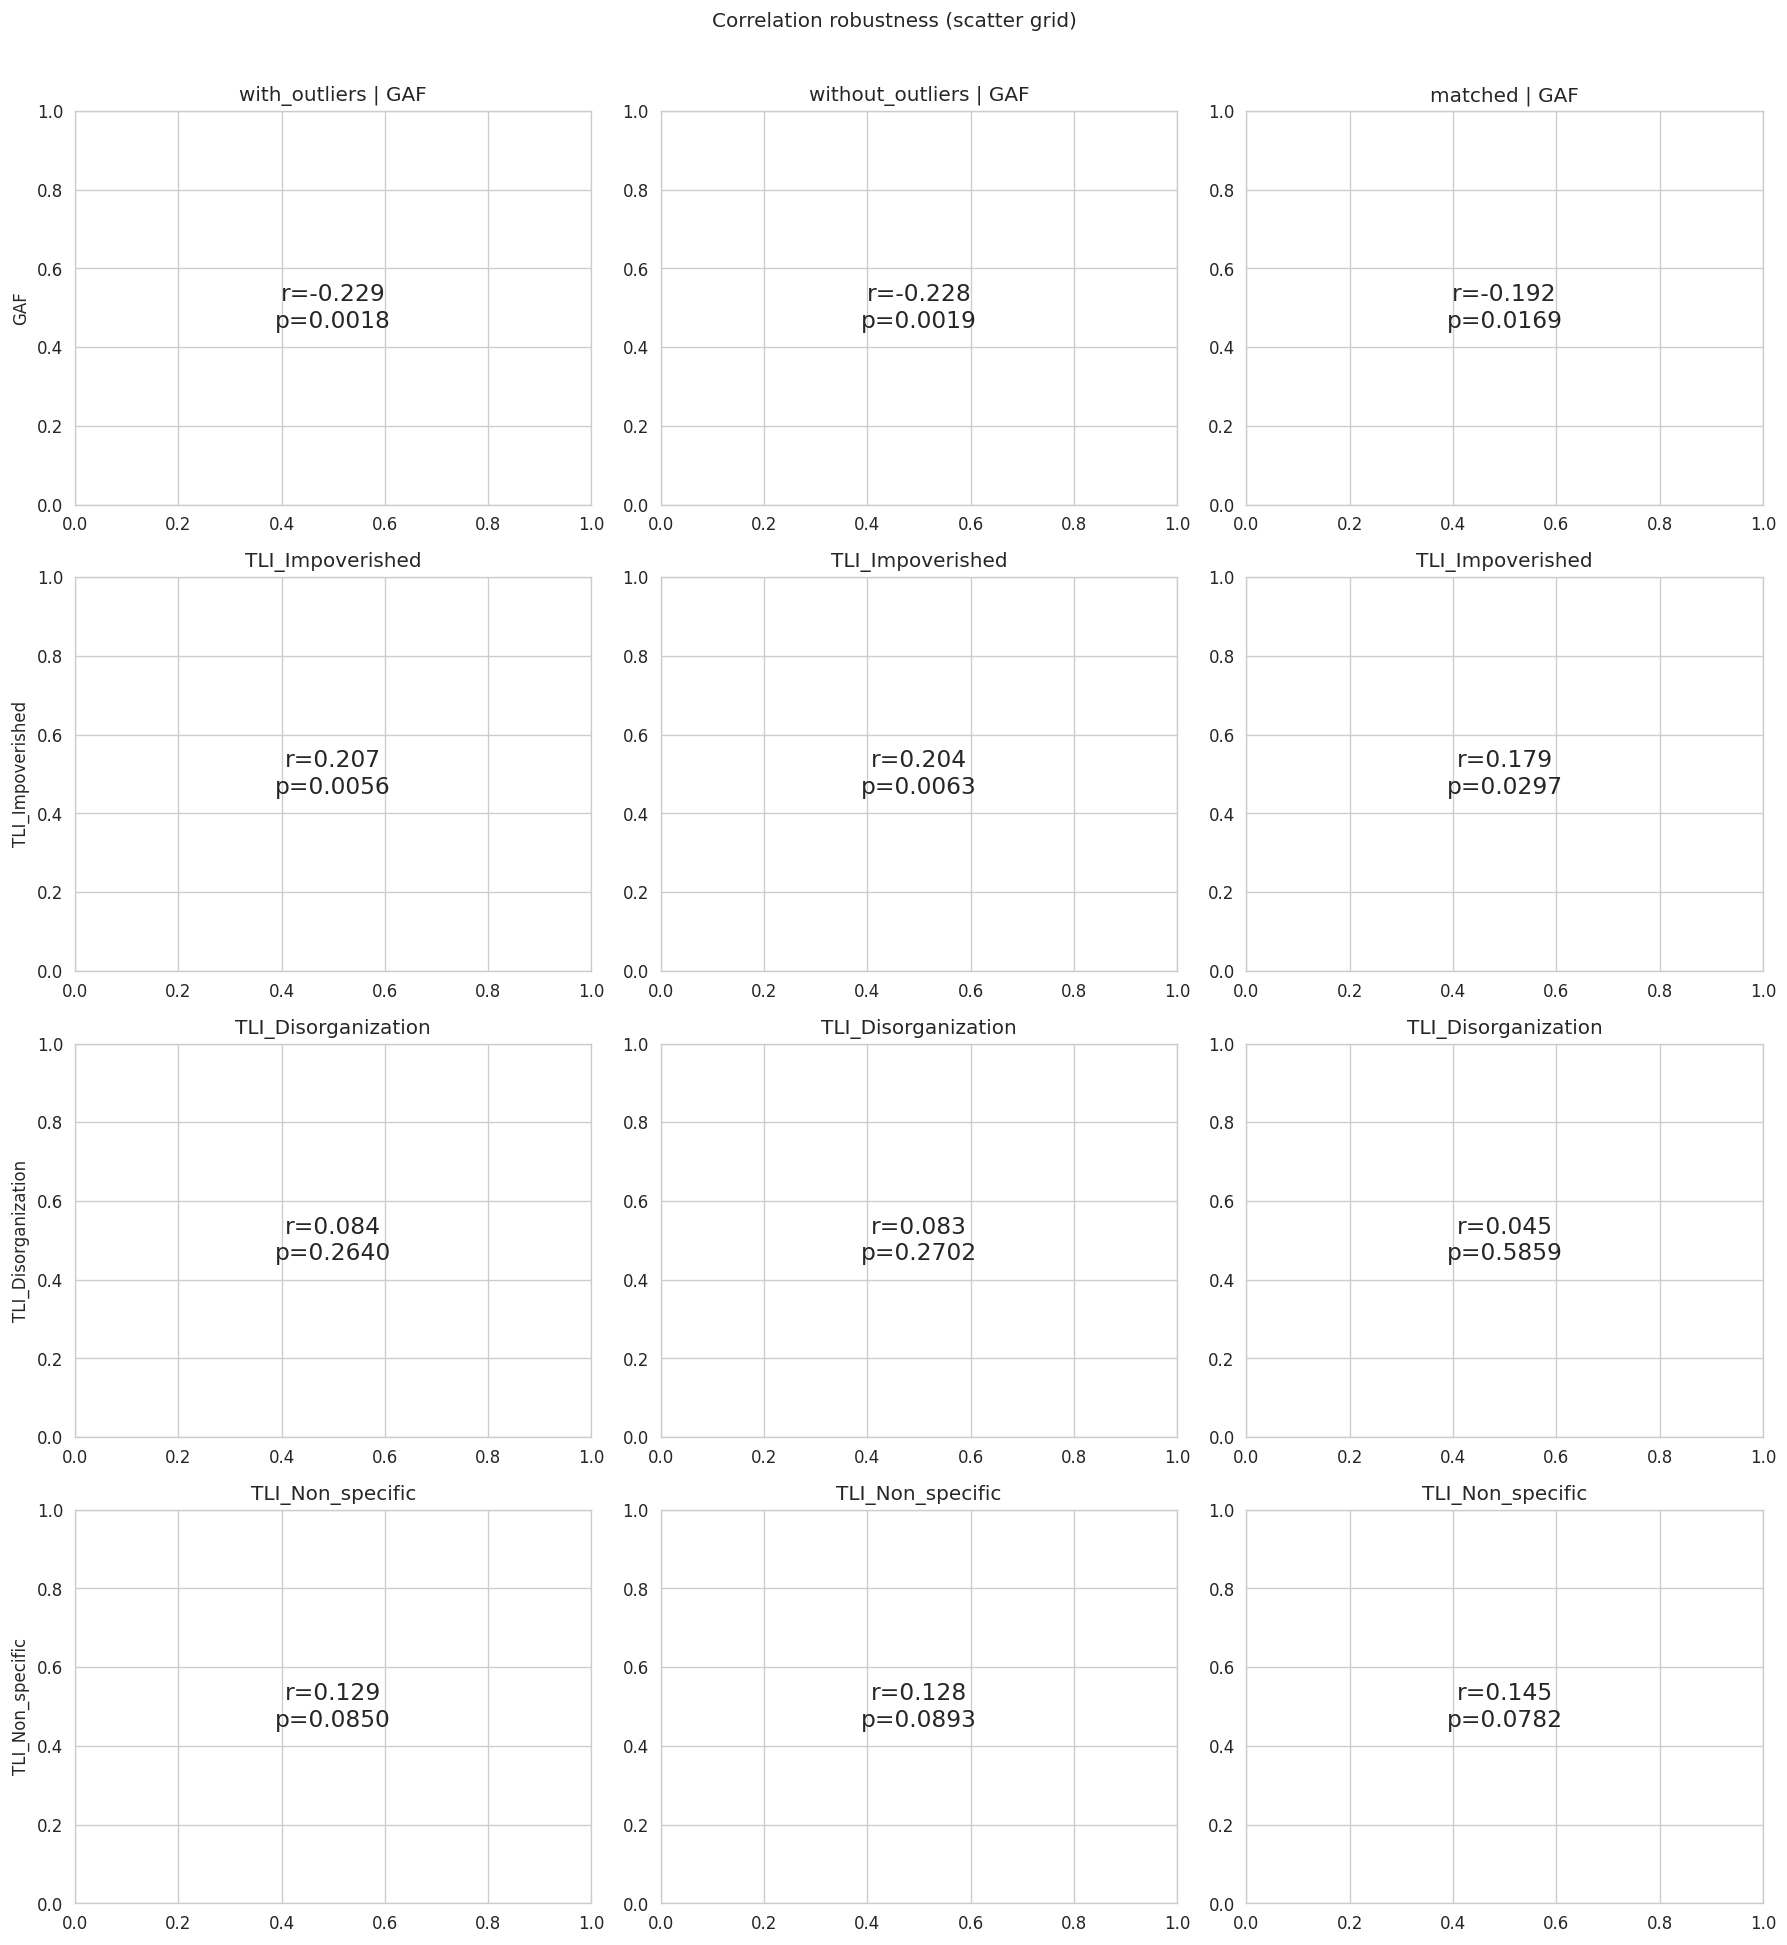

In [38]:
plot_cross_setting(all_corr_dfs, figure_dir=FIGURE_DIR)

In [39]:
# Summary table of all comparisons (raw + deconfounded)
summary_rows = []
for sname, res in all_results.items():
    row_raw = {"Setting": sname, "Analysis": "Raw"}
    row_raw.update(res["comparison"])
    summary_rows.append(row_raw)
    if "deconfounded" in res:
        row_resid = {"Setting": sname, "Analysis": "Residualized"}
        row_resid.update(res["deconfounded"]["comparison_resid"])
        summary_rows.append(row_resid)
summary_df = pd.DataFrame(summary_rows)
summary_df

,Setting,Analysis,Variable,Control (M±SD),Patient (M±SD),Control Median,Patient Median,t,p(t),U,p(MW),Cohens d,r
0,with_outliers,Raw,qwen_ppl_median,41.24±14.06,47.29±19.22,39.009001,44.747772,3.415535,0.000708,20114.0,0.000812,0.357258,-0.202523
1,with_outliers,Residualized,qwen_ppl_median_resid,-1.78±13.44,1.66±17.82,-2.499279,-0.356828,2.031086,0.043006,16961.0,0.078190,0.217260,-0.108961
2,without_outliers,Raw,qwen_ppl_median_wins,41.07±12.56,46.09±14.77,39.009001,44.747772,3.496232,0.000530,20120.0,0.000794,0.365699,-0.202882
3,without_outliers,Residualized,qwen_ppl_median_wins_resid,-1.54±11.69,1.44±13.70,-2.501413,0.162877,2.175934,0.030232,17275.0,0.036327,0.232754,-0.129491
4,matched,Raw,qwen_ppl_median,41.01±14.03,45.16±16.99,39.009001,43.008924,2.359803,0.018900,14317.0,0.013271,0.266343,-0.161670
5,matched,Residualized,qwen_ppl_median_resid,-1.53±13.69,1.53±16.14,-2.741692,0.269437,1.808964,0.071419,13902.0,0.049937,0.204171,-0.127997


## 5. Alternative metrics comparison

In [40]:
alt_metrics = [
    f"{MODEL}_ppl_median", f"{MODEL}_ppl_mean",
    f"{MODEL}_ppl_p90", f"{MODEL}_ppl_p75",
    f"{MODEL}_ppl_std", f"{MODEL}_ppl_cv",
    f"{MODEL}_prop_high_ppl",
]

# Group comparison for each metric
alt_comp = pd.DataFrame([group_comparison(df, m) for m in alt_metrics if m in df.columns])
alt_comp

,Variable,Control (M±SD),Patient (M±SD),Control Median,Patient Median,t,p(t),U,p(MW),Cohens d,r
0,qwen_ppl_median,41.24±14.06,47.29±19.22,39.009001,44.747772,3.415535,0.000708,20114.0,0.000812,0.357258,-0.202523
1,qwen_ppl_mean,260.33±781.91,254.84±679.84,124.129329,135.208871,-0.071795,0.942805,17051.0,0.748725,-0.007510,-0.019400
2,qwen_ppl_p90,301.74±346.37,280.57±292.12,175.221733,200.815132,-0.633472,0.526823,18001.5,0.207660,-0.066260,-0.076226
3,qwen_ppl_p75,97.26±117.26,101.16±58.58,75.152586,87.442347,0.406221,0.684819,19613.0,0.004328,0.042490,-0.172570
4,qwen_ppl_std,1201.76±5571.50,1075.85±4256.40,326.211863,320.892960,-0.243856,0.807480,16421.0,0.763005,-0.025507,0.018264
5,qwen_ppl_cv,2.81±1.63,2.64±1.50,2.419978,2.312631,-1.007354,0.314434,15831.0,0.376245,-0.105367,0.053538
6,qwen_prop_high_ppl,0.09±0.07,0.10±0.07,0.077922,0.098039,1.608631,0.108564,18545.0,0.072232,0.168259,-0.108720


Saved: figures/advanced/metrics_heatmap.png


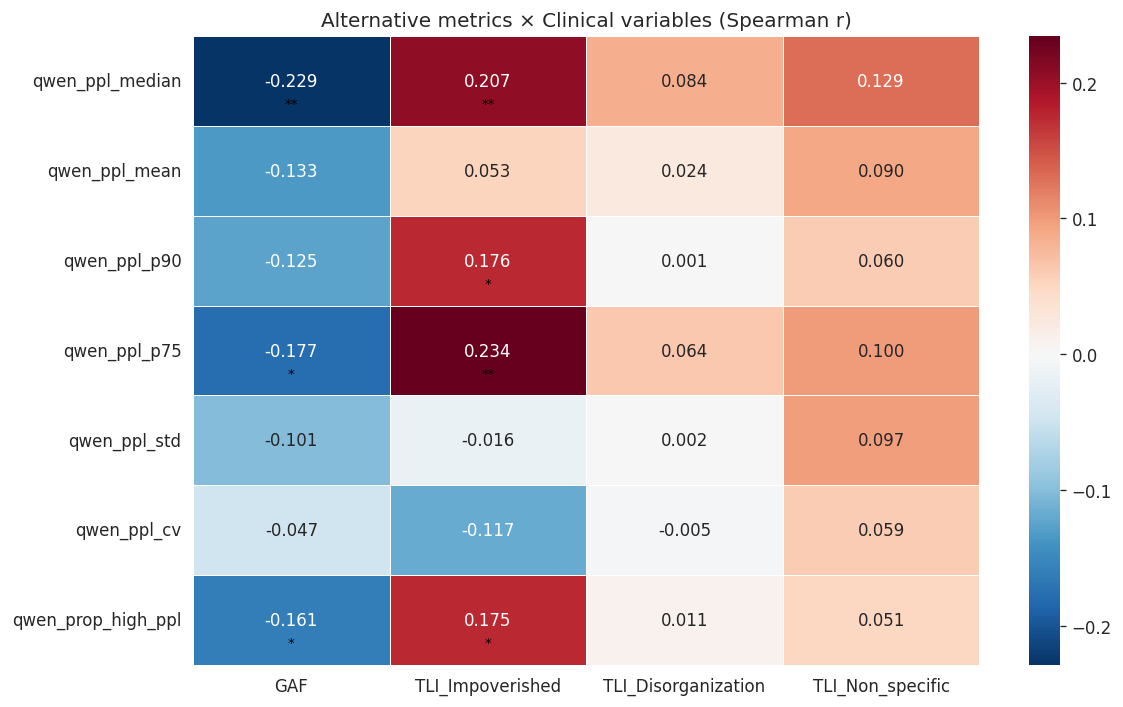

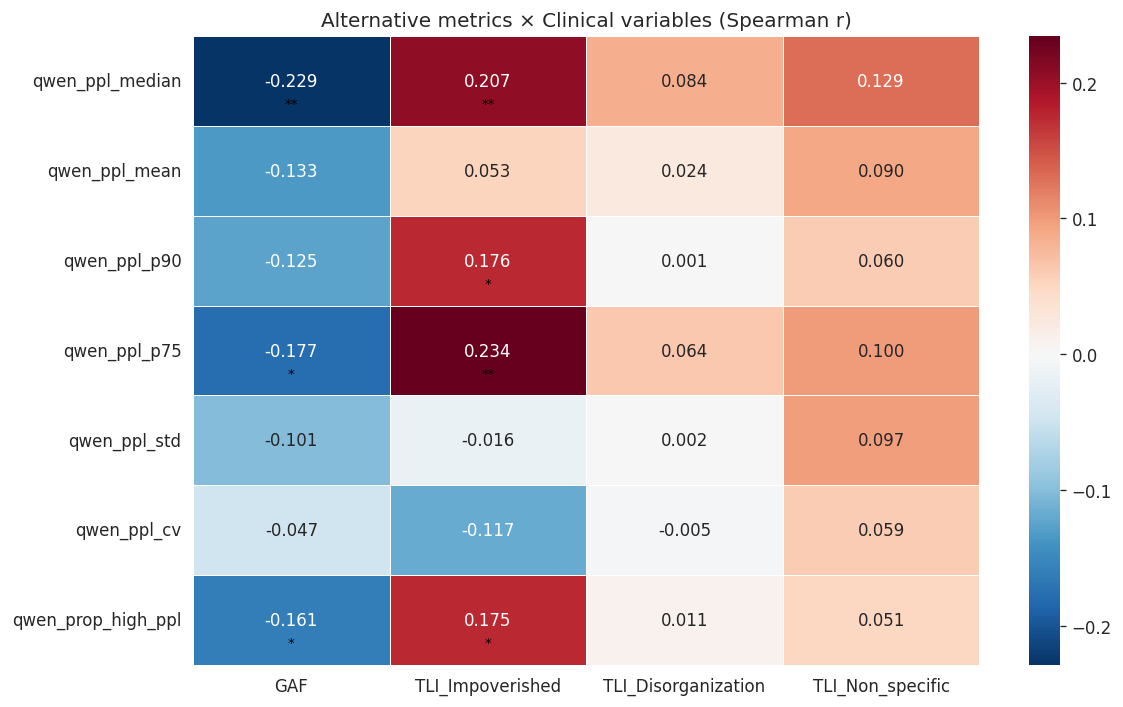

In [41]:
# Correlation heatmap: metrics × clinical variables
patients = df[df['is_patient'] == 1].copy()
r_matrix = pd.DataFrame(index=[m for m in alt_metrics if m in df.columns], columns=clinical_vars, dtype=float)
p_matrix = r_matrix.copy()

for metric in r_matrix.index:
    for cvar in clinical_vars:
        sub = patients[[metric, cvar]].dropna()
        if len(sub) >= 5:
            r, p = spearmanr(sub[metric], sub[cvar])
            r_matrix.loc[metric, cvar] = r
            p_matrix.loc[metric, cvar] = p

plot_metrics_heatmap(
    r_matrix.astype(float),
    p_matrix.astype(float),
    title="Alternative metrics × Clinical variables (Spearman r)",
    save_path=os.path.join(FIGURE_DIR, "advanced", "metrics_heatmap.png"),
)

## 6. TLI subscale analysis (Steiger's Z)

In [42]:
tli_metrics = [PPL_VAR, f"{MODEL}_ppl_p90", f"{MODEL}_prop_high_ppl"]
tli_vars = ["TLI_Impoverished", "TLI_Disorganization", "TLI_Non_specific"]

for metric in tli_metrics:
    sub = patients[[metric] + tli_vars].dropna()
    if len(sub) < 10:
        continue
    r_imp, _ = spearmanr(sub[metric], sub["TLI_Impoverished"])
    r_dis, _ = spearmanr(sub[metric], sub["TLI_Disorganization"])
    r_id, _ = spearmanr(sub["TLI_Impoverished"], sub["TLI_Disorganization"])
    z, p = steigers_z(r_imp, r_dis, r_id, len(sub))
    print(f"{metric}: r_imp={r_imp:.3f}, r_dis={r_dis:.3f}, Steiger Z={z:.3f}, p={p:.4f}")

qwen_ppl_median: r_imp=0.207, r_dis=0.084, Steiger Z=1.102, p=0.2706
qwen_ppl_p90: r_imp=0.176, r_dis=0.001, Steiger Z=1.560, p=0.1188
qwen_prop_high_ppl: r_imp=0.175, r_dis=0.011, Steiger Z=1.459, p=0.1447


## 7. ROC analysis

  GAF < 60 | qwen_ppl_median: AUC=0.562
  GAF < 60 | qwen_ppl_p90: AUC=0.504
  GAF < 60 | qwen_prop_high_ppl: AUC=0.526
  TLI Disorganization > 0 | qwen_ppl_median: AUC=0.614
  TLI Disorganization > 0 | qwen_ppl_p90: AUC=0.562
  TLI Disorganization > 0 | qwen_prop_high_ppl: AUC=0.560
  TLI Impoverished > 0 | qwen_ppl_median: AUC=0.616
  TLI Impoverished > 0 | qwen_ppl_p90: AUC=0.611
  TLI Impoverished > 0 | qwen_prop_high_ppl: AUC=0.618
Saved: figures/advanced/roc_curves.png


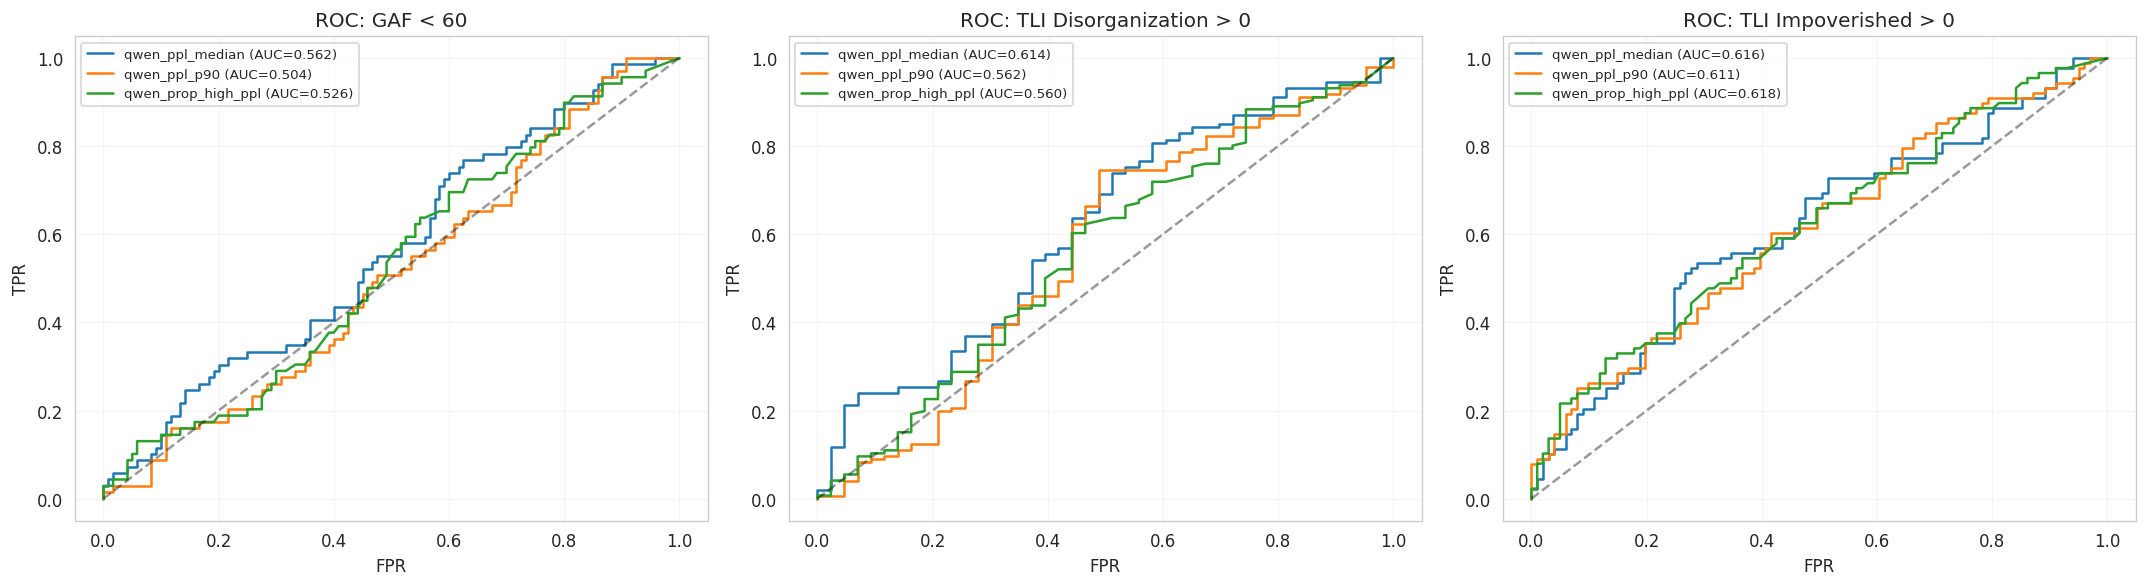

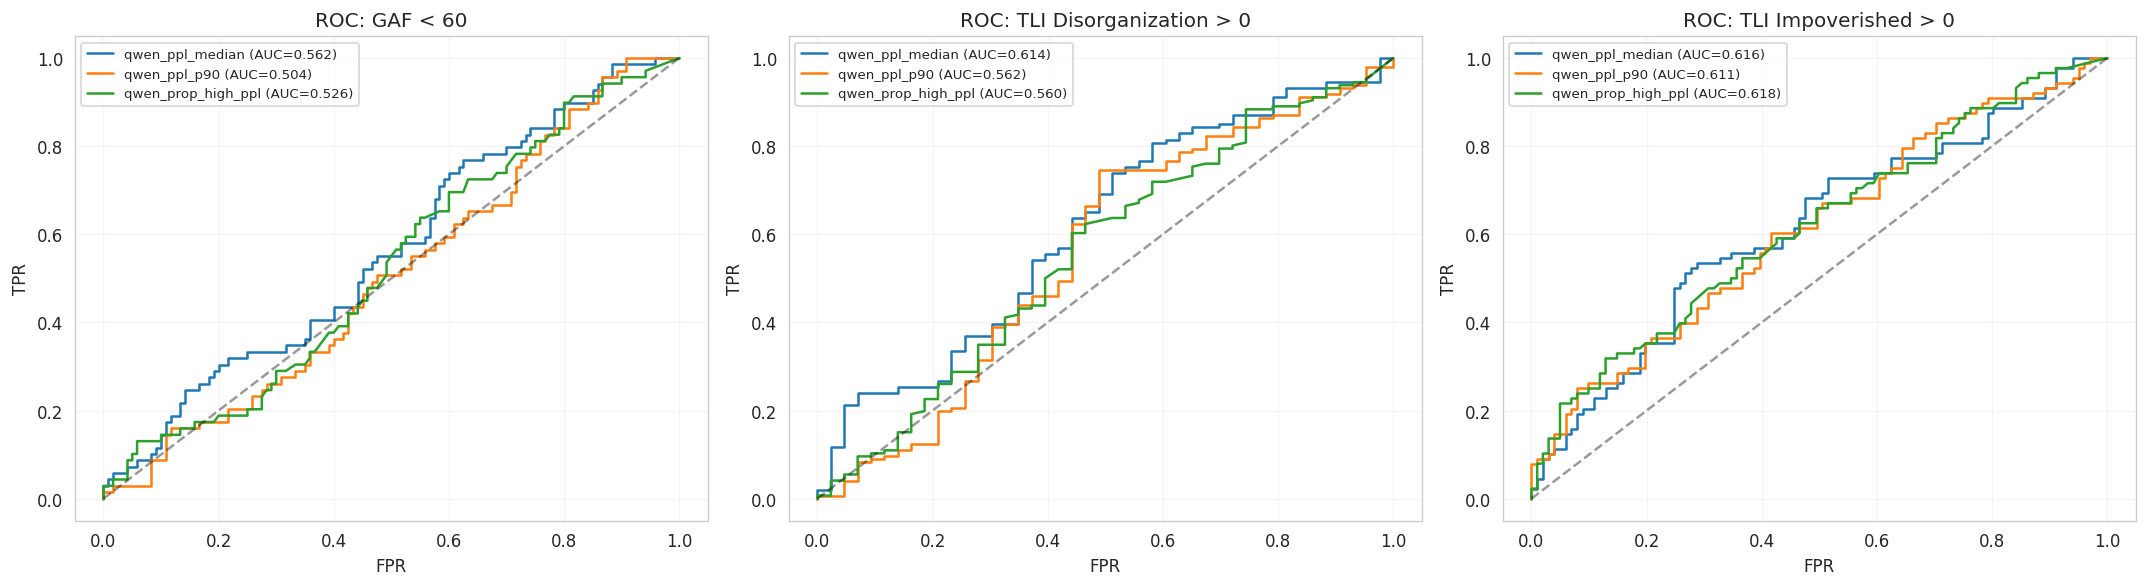

In [43]:
# Define clinical impairment targets
patients = df[df['is_patient'] == 1].copy()
patients['GAF_impaired'] = (patients['GAF'] < 60).astype(int)
patients['TLI_dis_any'] = (patients['TLI_Disorganization'] > 0).astype(int)
patients['TLI_imp_any'] = (patients['TLI_Impoverished'] > 0).astype(int)

ppl_roc_metrics = [PPL_VAR, f"{MODEL}_ppl_p90", f"{MODEL}_prop_high_ppl"]
roc_targets = {
    'GAF < 60': 'GAF_impaired',
    'TLI Disorganization > 0': 'TLI_dis_any',
    'TLI Impoverished > 0': 'TLI_imp_any',
}

all_rocs = {}
for target_label, target_col in roc_targets.items():
    rocs = compute_roc(patients, ppl_roc_metrics, target_col)
    all_rocs[target_label] = rocs
    for r in rocs:
        print(f"  {target_label} | {r['metric']}: AUC={r['auc']:.3f}")

plot_roc_curves(
    [],  # not used directly
    all_rocs,
    save_path=os.path.join(FIGURE_DIR, "advanced", "roc_curves.png"),
)

In [44]:
# Combined metric: logistic regression CV
features_combined = [PPL_VAR, f"{MODEL}_ppl_std", f"{MODEL}_prop_high_ppl"]
for target_label, target_col in roc_targets.items():
    auc_combined = logistic_cv_auc(patients, features_combined, target_col)
    auc_singles = {m: logistic_cv_auc(patients, [m], target_col) for m in features_combined}
    print(f"{target_label}: combined AUC={auc_combined:.3f}")
    for m, a in auc_singles.items():
        print(f"  single {m}: AUC={a:.3f}")

GAF < 60: combined AUC=0.554
  single qwen_ppl_median: AUC=0.566
  single qwen_ppl_std: AUC=0.585
  single qwen_prop_high_ppl: AUC=0.521
TLI Disorganization > 0: combined AUC=0.587
  single qwen_ppl_median: AUC=0.602
  single qwen_ppl_std: AUC=0.414
  single qwen_prop_high_ppl: AUC=0.558
TLI Impoverished > 0: combined AUC=0.622
  single qwen_ppl_median: AUC=0.614
  single qwen_ppl_std: AUC=0.521
  single qwen_prop_high_ppl: AUC=0.627


## 8. Confounder analysis

Saved: figures/advanced/confounder_analysis.png


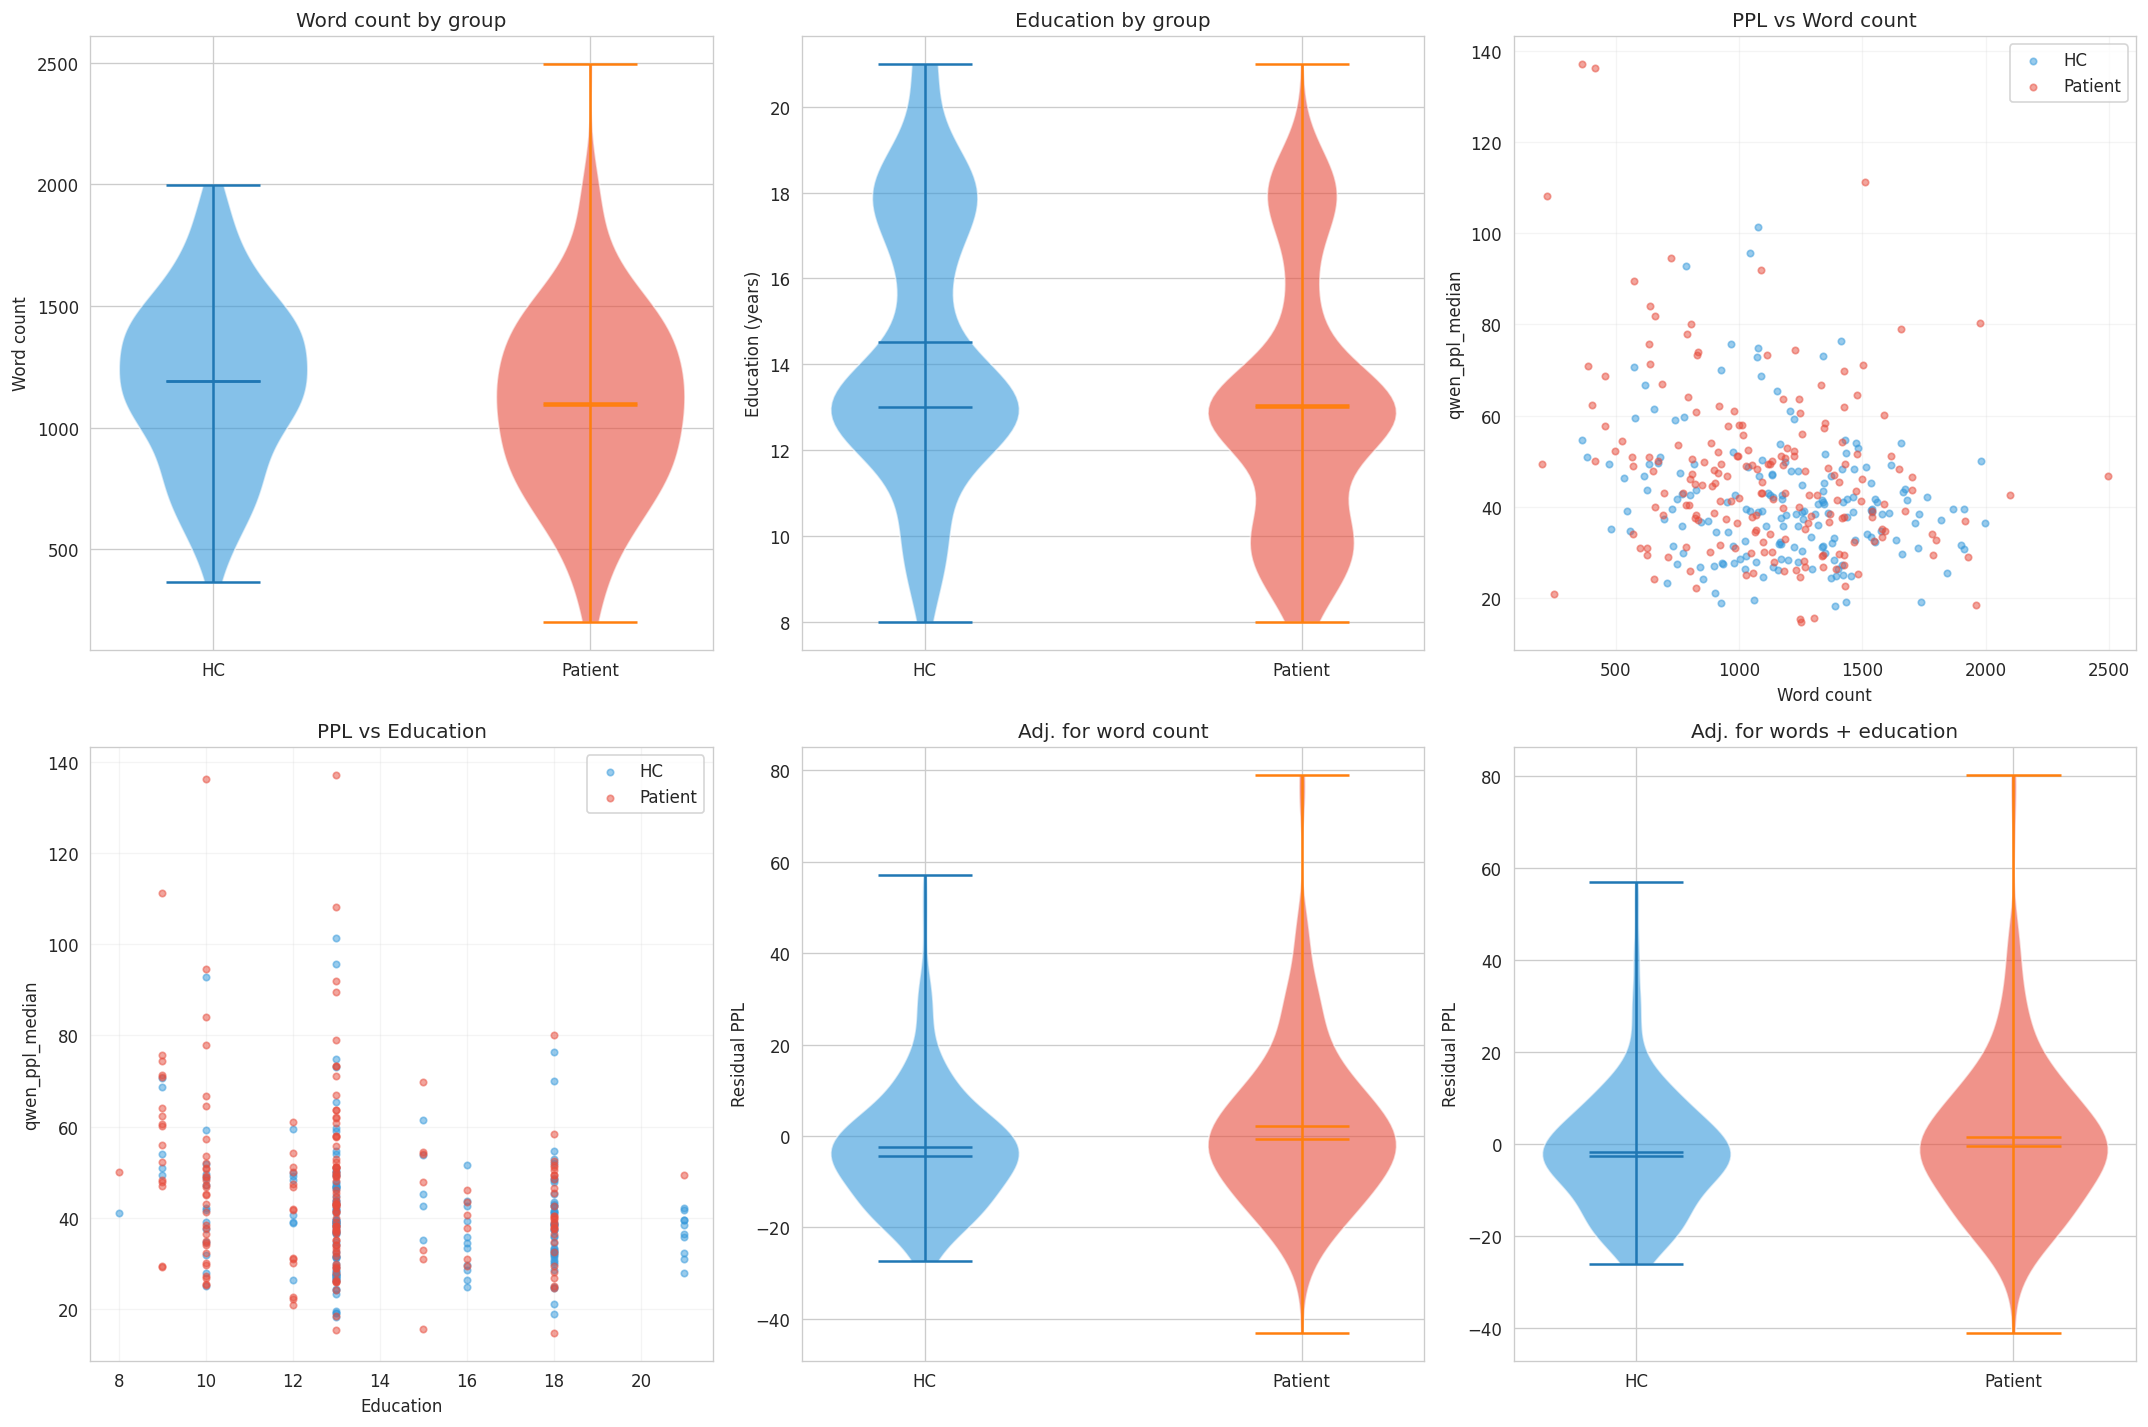

Saved: figures/advanced/raw_vs_residualized.png


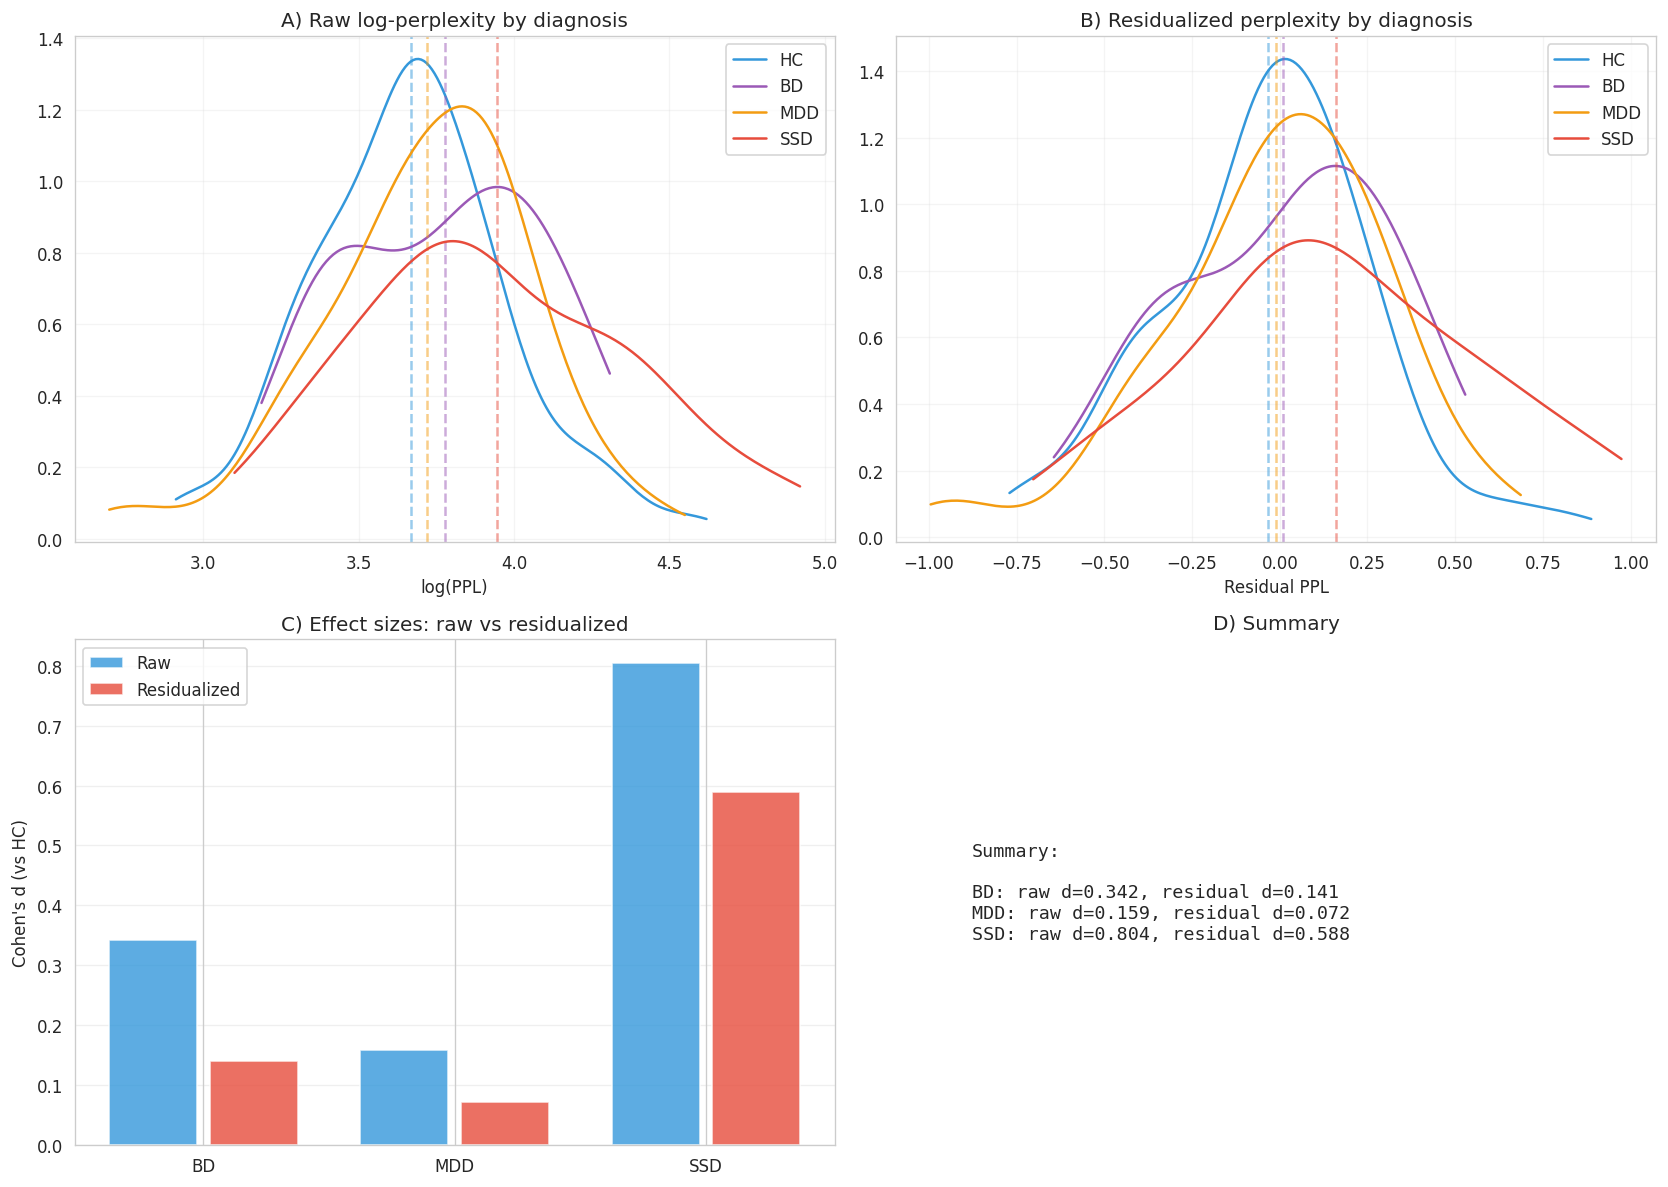

Saved: figures/advanced/raw_perplexity_basic.png


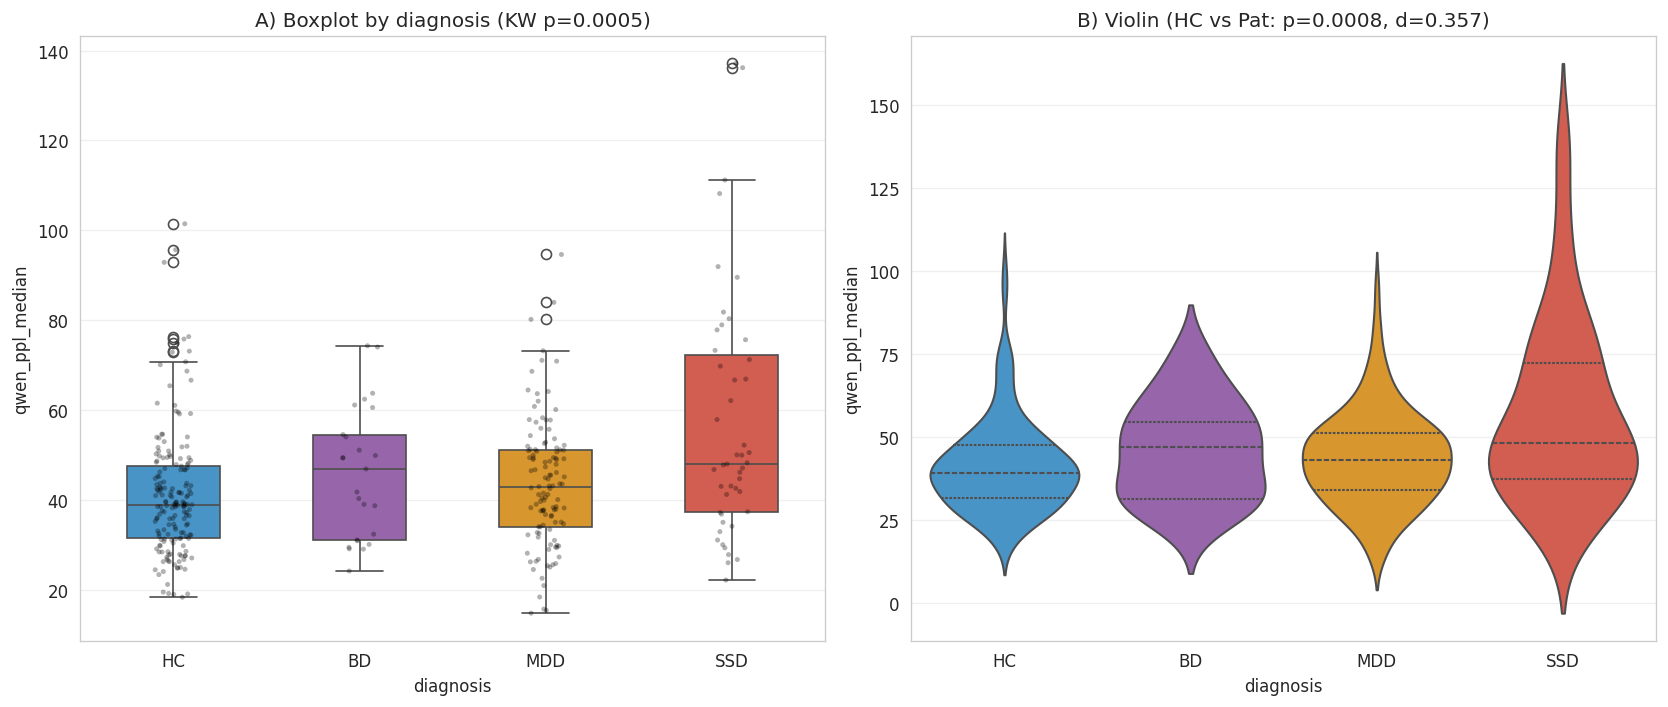

In [45]:
# Confounder visualisation
plot_advanced(
    df=df,
    patients=patients,
    ppl_var=PPL_VAR,
    wc_var=WC_VAR,
    figure_dir=FIGURE_DIR,
)

### 8b. Deconfounding: residualize PPL, then re-run group comparisons & clinical correlations

Instead of nested ANOVA (where confounders absorb the group signal), we regress out
confounders (log word count + education) from perplexity and then test the **residualized**
perplexity for group differences and clinical associations.

In [46]:
# ── Residualize perplexity ────────────────────────────────────────
# Regress out log(word_count) + education from PPL, keep the residuals.
import statsmodels.api as sm

df_deconf = df.copy()
df_deconf["log_words"] = np.log1p(df_deconf[WC_VAR])

confounders = ["log_words"]
if "education" in df_deconf.columns:
    confounders.append("education")

df_deconf[f"{PPL_VAR}_resid"] = np.nan
resid = residualize_ppl(df_deconf, PPL_VAR, confounders)
df_deconf.loc[resid.index, f"{PPL_VAR}_resid"] = resid

RESID_VAR = f"{PPL_VAR}_resid"
print(f"Confounders removed: {confounders}")
print(f"Residualized variable: {RESID_VAR}")
print(f"N with residuals: {df_deconf[RESID_VAR].notna().sum()}")

# ── Group comparison: raw vs residualized ────────────────────────
print("\n" + "=" * 60)
print("GROUP COMPARISON — Raw PPL")
print("=" * 60)
comp_raw = group_comparison(df_deconf, PPL_VAR)
for k, v in comp_raw.items():
    print(f"  {k}: {v}")

print("\n" + "=" * 60)
print("GROUP COMPARISON — Residualized PPL")
print("=" * 60)
comp_resid = group_comparison(df_deconf.dropna(subset=[RESID_VAR]), RESID_VAR)
for k, v in comp_resid.items():
    print(f"  {k}: {v}")

# Summary table
comp_summary = pd.DataFrame([
    {"Metric": "Raw PPL", **{k: v for k, v in comp_raw.items() if k != "Variable"}},
    {"Metric": "Residualized PPL", **{k: v for k, v in comp_resid.items() if k != "Variable"}},
])
comp_summary

Confounders removed: ['log_words', 'education']
Residualized variable: qwen_ppl_median_resid
N with residuals: 350

GROUP COMPARISON — Raw PPL
  Variable: qwen_ppl_median
  Control (M±SD): 41.24±14.06
  Patient (M±SD): 47.29±19.22
  Control Median: 39.0090008613624
  Patient Median: 44.74777198748531
  t: 3.4155346940237017
  p(t): 0.0007083850798510544
  U: 20114.0
  p(MW): 0.0008123903292220418
  Cohens d: 0.3572577909969567
  r: -0.20252294263593695

GROUP COMPARISON — Residualized PPL
  Variable: qwen_ppl_median_resid
  Control (M±SD): -1.78±13.44
  Patient (M±SD): 1.66±17.82
  Control Median: -2.499278726139792
  Patient Median: -0.35682781103940187
  t: 2.0310857732259215
  p(t): 0.04300597459828797
  U: 16961.0
  p(MW): 0.07819032461216652
  Cohens d: 0.21725993565781204
  r: -0.10896073752002344


,Metric,Control (M±SD),Patient (M±SD),Control Median,Patient Median,t,p(t),U,p(MW),Cohens d,r
0,Raw PPL,41.24±14.06,47.29±19.22,39.009001,44.747772,3.415535,0.000708,20114.0,0.000812,0.357258,-0.202523
1,Residualized PPL,-1.78±13.44,1.66±17.82,-2.499279,-0.356828,2.031086,0.043006,16961.0,0.078190,0.217260,-0.108961


In [47]:
# ── Clinical correlations: raw vs residualized ───────────────────
patients_deconf = df_deconf[df_deconf["is_patient"] == 1].copy()

print("CLINICAL CORRELATIONS — Raw PPL (patients only)")
corr_raw = clinical_correlations(patients_deconf, PPL_VAR, clinical_vars)
print(corr_raw.to_string(index=False))

print("\nCLINICAL CORRELATIONS — Residualized PPL (patients only)")
corr_resid = clinical_correlations(
    patients_deconf.dropna(subset=[RESID_VAR]), RESID_VAR, clinical_vars
)
print(corr_resid.to_string(index=False))

# Side-by-side comparison
merged_corr = corr_raw.merge(
    corr_resid, on="Clinical Variable", suffixes=("_raw", "_resid")
)
merged_corr

CLINICAL CORRELATIONS — Raw PPL (patients only)
  Clinical Variable         r        p   n
                GAF -0.228861 0.001832 183
   TLI_Impoverished  0.206831 0.005605 178
TLI_Disorganization  0.084169 0.263985 178
   TLI_Non_specific  0.129458 0.085021 178

CLINICAL CORRELATIONS — Residualized PPL (patients only)
  Clinical Variable         r        p   n
                GAF -0.114804 0.129212 176
   TLI_Impoverished -0.003757 0.961215 170
TLI_Disorganization  0.143937 0.061119 170
   TLI_Non_specific  0.125981 0.101629 170


,Clinical Variable,r_raw,p_raw,n_raw,r_resid,p_resid,n_resid
0,GAF,-0.228861,0.001832,183,-0.114804,0.129212,176
1,TLI_Impoverished,0.206831,0.005605,178,-0.003757,0.961215,170
2,TLI_Disorganization,0.084169,0.263985,178,0.143937,0.061119,170
3,TLI_Non_specific,0.129458,0.085021,178,0.125981,0.101629,170


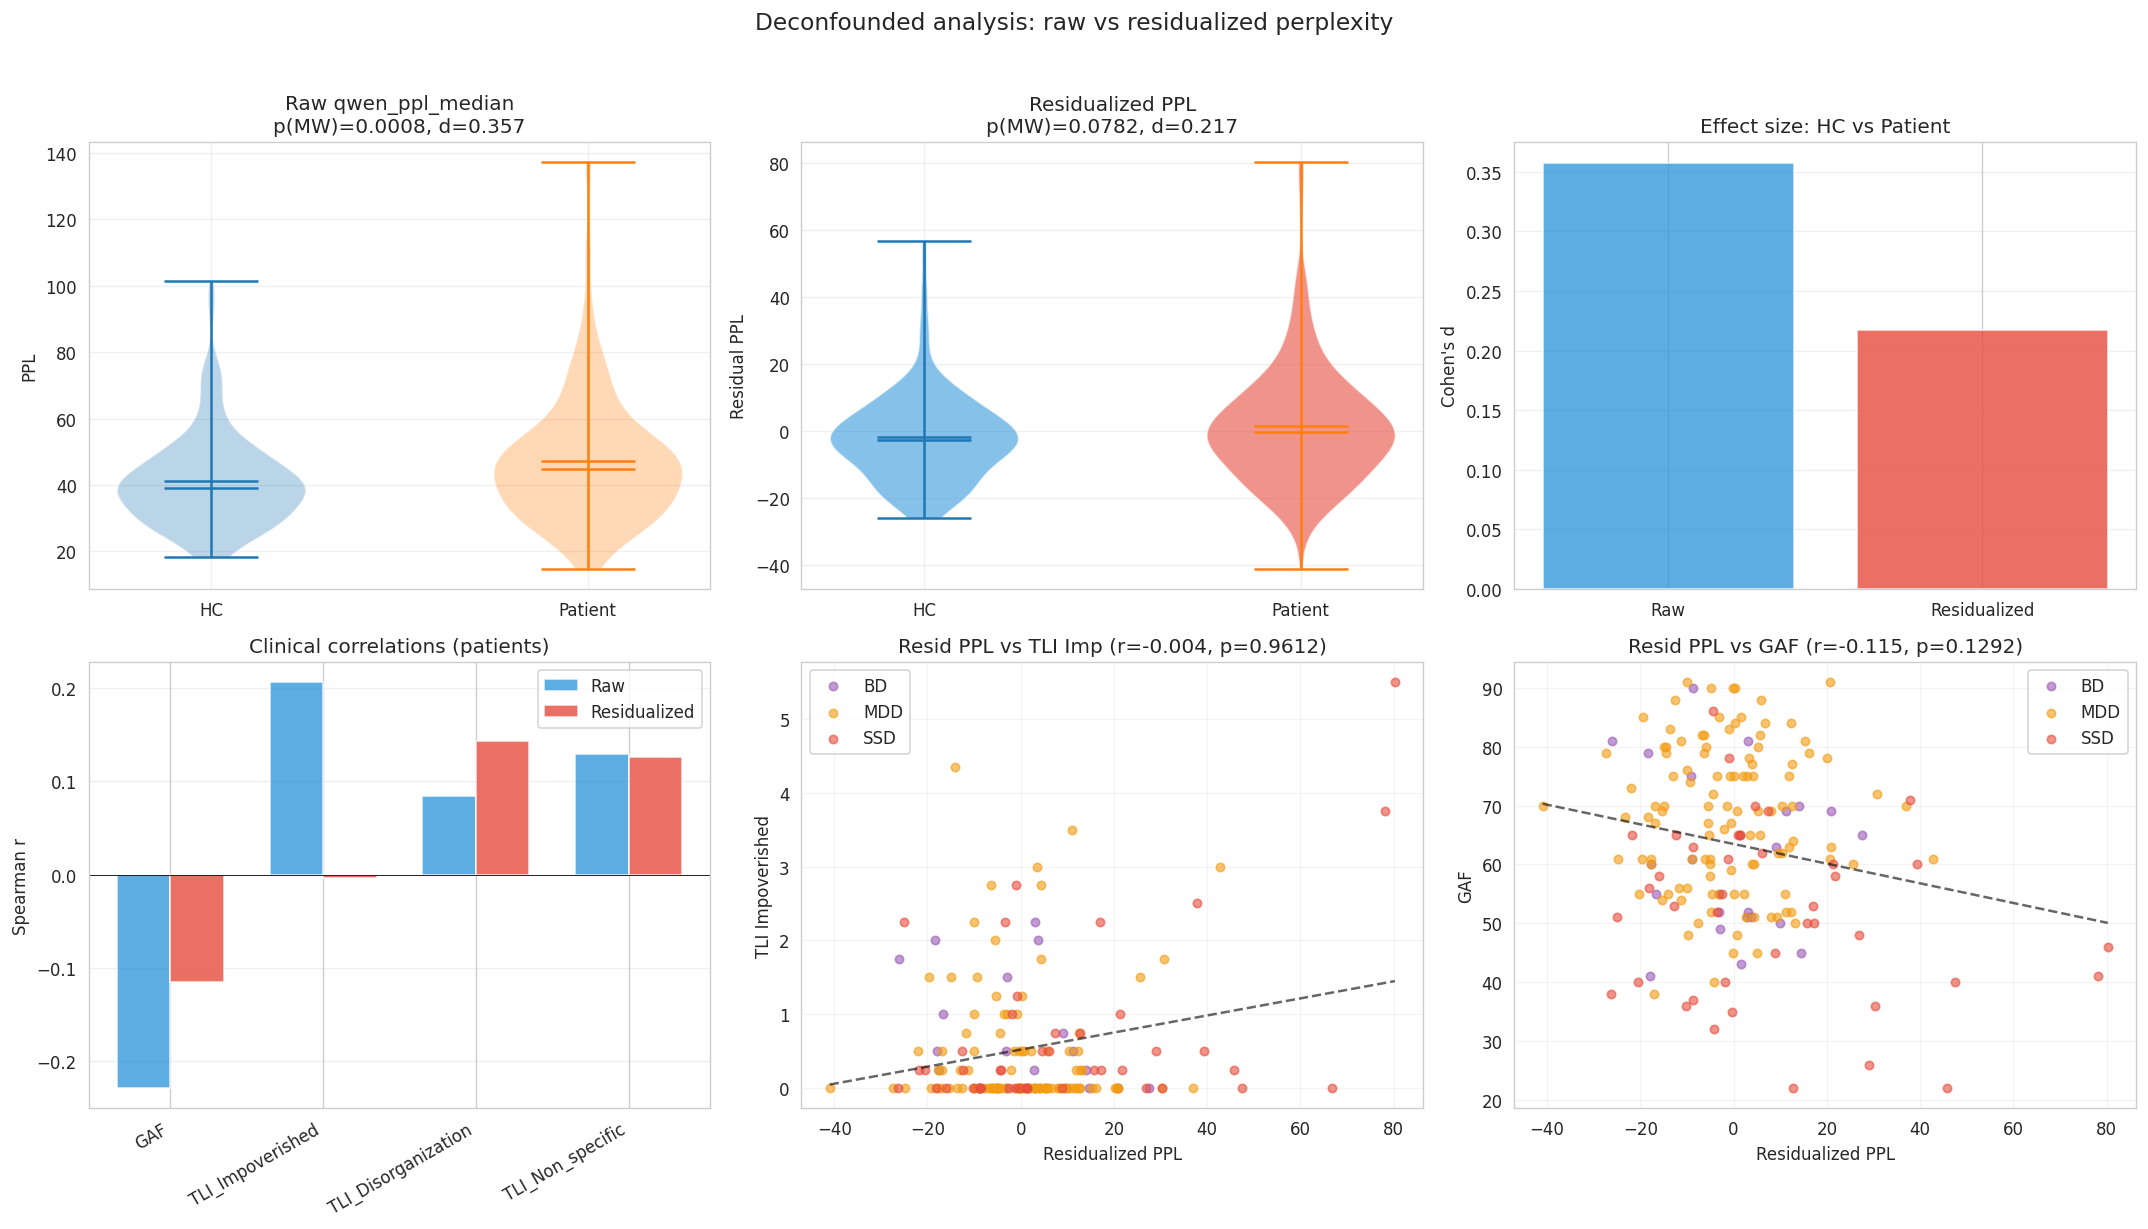

In [48]:
# ── Visualisation: raw vs residualized ────────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Row 1: Raw PPL
ax = axes[0, 0]
for is_pat, lbl, clr in [(0, "HC", "#3498DB"), (1, "Patient", "#E74C3C")]:
    vals = df_deconf[df_deconf["is_patient"] == is_pat][PPL_VAR].dropna()
    ax.violinplot([vals], positions=[is_pat], showmeans=True, showmedians=True)
ax.set_xticks([0, 1]); ax.set_xticklabels(["HC", "Patient"])
ax.set_title(f"Raw {PPL_VAR}\np(MW)={comp_raw['p(MW)']:.4f}, d={comp_raw['Cohens d']:.3f}")
ax.set_ylabel("PPL"); ax.grid(alpha=0.3)

# Row 1: Residualized PPL
ax = axes[0, 1]
for is_pat, lbl, clr in [(0, "HC", "#3498DB"), (1, "Patient", "#E74C3C")]:
    vals = df_deconf[df_deconf["is_patient"] == is_pat][RESID_VAR].dropna()
    parts = ax.violinplot([vals], positions=[is_pat], showmeans=True, showmedians=True)
    for pc in parts["bodies"]:
        pc.set_facecolor(clr); pc.set_alpha(0.6)
ax.set_xticks([0, 1]); ax.set_xticklabels(["HC", "Patient"])
ax.set_title(f"Residualized PPL\np(MW)={comp_resid['p(MW)']:.4f}, d={comp_resid['Cohens d']:.3f}")
ax.set_ylabel("Residual PPL"); ax.grid(alpha=0.3)

# Row 1: Cohen's d comparison
ax = axes[0, 2]
ax.bar(["Raw", "Residualized"], [comp_raw["Cohens d"], comp_resid["Cohens d"]],
       color=["#3498DB", "#E74C3C"], alpha=0.8)
ax.set_ylabel("Cohen's d"); ax.set_title("Effect size: HC vs Patient")
ax.grid(axis="y", alpha=0.3); ax.axhline(0, color="black", lw=0.5)

# Row 2: Clinical correlations comparison
ax = axes[1, 0]
x = np.arange(len(clinical_vars))
w = 0.35
bars_raw = merged_corr.set_index("Clinical Variable").reindex(clinical_vars)["r_raw"]
bars_res = merged_corr.set_index("Clinical Variable").reindex(clinical_vars)["r_resid"]
ax.bar(x - w/2, bars_raw, w, label="Raw", color="#3498DB", alpha=0.8)
ax.bar(x + w/2, bars_res, w, label="Residualized", color="#E74C3C", alpha=0.8)
ax.set_xticks(x); ax.set_xticklabels(clinical_vars, rotation=30, ha="right")
ax.set_ylabel("Spearman r"); ax.set_title("Clinical correlations (patients)")
ax.legend(); ax.axhline(0, color="black", lw=0.5); ax.grid(axis="y", alpha=0.3)

# Row 2: Scatter — residualized PPL vs TLI Impoverished
ax = axes[1, 1]
sub = patients_deconf[[RESID_VAR, "TLI_Impoverished", "diagnosis"]].dropna()
if len(sub) >= 5:
    from functions.plotting.plots import DIAG_ORDER, DIAG_COLORS
    diags = [d for d in DIAG_ORDER if d in sub["diagnosis"].values]
    for dx in diags:
        s = sub[sub["diagnosis"] == dx]
        ax.scatter(s[RESID_VAR], s["TLI_Impoverished"], color=DIAG_COLORS.get(dx, "#888"),
                   label=dx, alpha=0.6, s=25)
    r, p = spearmanr(sub[RESID_VAR], sub["TLI_Impoverished"])
    z = np.polyfit(sub[RESID_VAR], sub["TLI_Impoverished"], 1)
    xs = np.linspace(sub[RESID_VAR].min(), sub[RESID_VAR].max(), 100)
    ax.plot(xs, np.polyval(z, xs), "k--", alpha=0.6)
    ax.set_xlabel("Residualized PPL"); ax.set_ylabel("TLI Impoverished")
    ax.set_title(f"Resid PPL vs TLI Imp (r={r:.3f}, p={p:.4f})")
    ax.legend(); ax.grid(alpha=0.2)

# Row 2: Scatter — residualized PPL vs GAF
ax = axes[1, 2]
sub = patients_deconf[[RESID_VAR, "GAF", "diagnosis"]].dropna()
if len(sub) >= 5:
    for dx in diags:
        s = sub[sub["diagnosis"] == dx]
        ax.scatter(s[RESID_VAR], s["GAF"], color=DIAG_COLORS.get(dx, "#888"),
                   label=dx, alpha=0.6, s=25)
    r, p = spearmanr(sub[RESID_VAR], sub["GAF"])
    z = np.polyfit(sub[RESID_VAR], sub["GAF"], 1)
    xs = np.linspace(sub[RESID_VAR].min(), sub[RESID_VAR].max(), 100)
    ax.plot(xs, np.polyval(z, xs), "k--", alpha=0.6)
    ax.set_xlabel("Residualized PPL"); ax.set_ylabel("GAF")
    ax.set_title(f"Resid PPL vs GAF (r={r:.3f}, p={p:.4f})")
    ax.legend(); ax.grid(alpha=0.2)

fig.suptitle("Deconfounded analysis: raw vs residualized perplexity", fontsize=14, y=1.02)
fig.tight_layout()
fig.savefig(os.path.join(FIGURE_DIR, "advanced", "deconfounded_analysis.png"),
            dpi=150, bbox_inches="tight")
plt.show()

In [49]:
# ── Per-diagnosis deconfounded comparison vs HC ──────────────────
from functions.analysis.statistics import pairwise_vs_hc, kruskal_wallis_test

print("PAIRWISE vs HC — Raw PPL")
pw_raw = pairwise_vs_hc(df_deconf, PPL_VAR)
print(pd.DataFrame(pw_raw).to_string(index=False))

print("\nPAIRWISE vs HC — Residualized PPL")
pw_resid = pairwise_vs_hc(df_deconf.dropna(subset=[RESID_VAR]), RESID_VAR)
print(pd.DataFrame(pw_resid).to_string(index=False))

print("\nKruskal-Wallis across diagnoses:")
kw_raw_stat, kw_raw_p = kruskal_wallis_test(df_deconf, PPL_VAR)
kw_res_stat, kw_res_p = kruskal_wallis_test(
    df_deconf.dropna(subset=[RESID_VAR]), RESID_VAR
)
print(f"  Raw:          H={kw_raw_stat:.3f}, p={kw_raw_p:.4f}")
print(f"  Residualized: H={kw_res_stat:.3f}, p={kw_res_p:.4f}")

PAIRWISE vs HC — Raw PPL
Diagnosis       U        p  Cohen's d   n
       BD  2656.0 0.105413   0.331342  25
      MDD 11751.0 0.050403   0.167210 117
      SSD  5707.0 0.000090   0.901713  47

PAIRWISE vs HC — Residualized PPL
Diagnosis       U        p  Cohen's d   n
       BD  2124.0 0.471581   0.095352  23
      MDD 10298.0 0.393273   0.063862 115
      SSD  4539.0 0.011741   0.688797  43

Kruskal-Wallis across diagnoses:
  Raw:          H=17.556, p=0.0005
  Residualized: H=6.881, p=0.0758


## 9. Summary

In [50]:
print("Analysis complete.")
print(f"Figures saved to: {os.path.abspath(FIGURE_DIR)}")

Analysis complete.
Figures saved to: /zi/home/esra.lenz/Documents/00_HITKIP/11_normative/mnm_ppl/figures
